In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

# import os
# for dirname, _, filenames in os.walk('/kaggle/input'):
#     for filename in filenames:
#         print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [2]:
import torch
import torch.nn as nn

In [3]:
class DynamicGraph(nn.Module):
    def __init__(self, feature_dim=64, max_nodes=1024, max_edges_per_node=8, input_size=64, output_size=2, hidden_layers=[128, 256, 256, 128, 64], device=None):
        super().__init__()
        if device==None:
            if hasattr(torch, "xpu") and torch.xpu.is_available():
                device = torch.device("xpu")
            elif torch.cuda.is_available():
                device = torch.device("cuda")
            else:
                device = torch.device("cpu")
        self.device = torch.device(device)
        print(f"\nUsing device : {device}\n")

        self.D = feature_dim
        self.max_nodes = max_nodes
        self.max_edges = max_nodes * max_edges_per_node
        # max_edges = self.max_edges
        self.max_edges_per_node = max_edges_per_node
        self.input_size = input_size
        self.output_size = output_size
        self.hidden_layers = hidden_layers
        self.max_rank = len(hidden_layers)

        ## Node Thingys

        # Node Weights (no_of_nodes, feature_dim)
        self.node_weight = nn.Parameter(
            torch.randn(
                max_nodes,
                feature_dim,
                device=self.device
            ) #* 0.02
        )

        # Node Pre Activation(Input of current node) (no_of_nodes,1)
        self.register_buffer(
            "node_pre_activation",
            torch.zeros(
                max_nodes,
                feature_dim,
                dtype=torch.float32,
                device=self.device
            )
        )

        # Node Activation(Input of current node) (no_of_nodes,1)
        self.register_buffer(
            "node_activation",
            torch.zeros(
                max_nodes,
                feature_dim,
                dtype=torch.float32,
                device=self.device
            )
        )

        # Node Bias (no_of_nodes,1)
        self.node_bias = nn.Parameter(
            torch.randn(
                max_nodes,
                feature_dim,
                device=self.device
            ) #* 0.02
        )

        # Node Active/Deactive (no_of_nodes,1)
        self.register_buffer(
            "node_alive",
            torch.zeros(
                max_nodes,
                dtype=torch.bool,
                device=self.device
            )
        )

        # Node Activation Type (Relu/Sigmoid/LRelu) (no_of_nodes,1)
        self.register_buffer(
            "node_activation_type",
            torch.zeros(
                max_nodes,
                dtype=torch.long,
                device=self.device
            )   
        )

        # Node Out Degree (no_of_nodes,1) (Value ranges from 0 to max_edges_per_node)
        self.register_buffer(
            "out_degree",
            torch.zeros(
                max_nodes,
                dtype=torch.long,
                device=self.device
            )
        )

        # Node In Degree (no_of_nodes,1) (Value ranges from 0 to no_of_nodes * max_edges_per_node)
        self.register_buffer(
            "in_degree",
            torch.zeros(
                max_nodes,
                dtype=torch.long,
                device=self.device
            )
        )

        # Node Rank (no_of_nodes,1)
        # Used to store the rank of nodes, which is used to prevent cycles
        self.register_buffer(
            "node_rank",
            torch.zeros(
                max_nodes,
                dtype=torch.long,
                device=self.device
            )
        )

        # No of current nodes (Includes Active + Deactive)
        self.nodes_count = 0


        ## Edge Thingys

        # Edge Source[edge_source][index] = edge_destination (no_of_nodes,max_edges_per_node)
        self.register_buffer(
            "edge_src",
            -1*torch.ones(
                max_nodes,
                max_edges_per_node,
                dtype=torch.long,
                device=self.device
            )
        )

        # Edge Index[edge_destination][index] = edge_source (no_of_nodes,max_edges_per_node)
        # Used to store the index of edge stored in edge_src matrix for quick operation in back prop
        self.register_buffer(
            "edge_index",
            -1*torch.ones(
                max_nodes,
                max_edges_per_node,
                dtype=torch.long,
                device=self.device
            )
        )

        # Edge Destination[edge_destination][index] = edge_source (no_of_nodes,max_edges_per_node)
        self.register_buffer(
            "edge_dest",
            -1*torch.ones(
                max_nodes,
                max_edges_per_node,
                dtype=torch.long,
                device=self.device
            )
        )

        # Edge Weight[edge_source][edge_destination] (no_of_nodes,max_edges_per_node)
        self.edge_weight = nn.Parameter(
            torch.randn(
                max_nodes,
                max_edges_per_node,
                device=self.device
            ) #* 0.02
        )

        # Edge Active/Deactive[edge_source][edge_destination] (no_of_nodes,max_edges_per_node)
        self.register_buffer(
            "edge_alive",
            torch.zeros(
                max_nodes,
                max_edges_per_node,
                dtype=torch.bool,
                device=self.device
            )   
        )

    @torch.no_grad()
    def add_node(self, activation=1):
        if self.nodes_count >= self.max_nodes:
            raise RuntimeError("Node capacity reached in Add Node"+str(self.max_nodes))
        index = self.nodes_count
        self.node_alive[index] = True
        self.node_activation_type[index] = activation
        self.nodes_count += 1
        return index

    @torch.no_grad()
    def remove_node(self, index):
        if index>=self.nodes_count or index<0:
            raise RuntimeError("Out of bound in Remove Node")

        self.node_alive[index] = False

    @torch.no_grad()
    def add_edge(self, source, destination):
        if source<0 or source>=self.nodes_count or destination<0 or destination>=self.nodes_count:
            raise RuntimeError("Out of bound in Add Edge 1st Thingy")
        if self.out_degree[source]>=self.max_edges_per_node or self.in_degree[destination]>=self.max_edges_per_node:
            raise RuntimeError("Out of bound in Add Edge 2nd Thingy")
        self.edge_src[source][self.out_degree[source]] = destination

        self.edge_index[destination][self.in_degree[destination]] = self.out_degree[source]
        self.edge_dest[destination][self.in_degree[destination]] = source

        self.edge_alive[source][self.out_degree[source]] = True

        self.out_degree[source] += 1
        self.in_degree[destination] += 1

    @torch.no_grad()
    def remove_edge(self, source, destination):
        if source<0 or source>=self.nodes_count or destination<0 or destination>=self.nodes_count:
            raise RuntimeError("Out of bound in Remove Edge")
        temp_index = self.edge_src[source]==destination
        self.edge_alive[source][temp_index] = False

    @torch.no_grad()
    def random_sample_source(self, start_index, end_index, target_size, destination_idx=None):
        source_idx = torch.zeros(target_size,dtype=torch.long,device=self.device)
        temp_idx = torch.arange(0,self.max_nodes,1,device=self.device)

        temp_idx = temp_idx[start_index:end_index][self.in_degree[start_index:end_index]<self.max_edges_per_node-1]
        
        temp_idx = temp_idx[torch.randperm(len(temp_idx))]
        source_idx[:min(len(temp_idx),target_size)] = temp_idx[:target_size]

        start, end = 0, min(len(temp_idx),target_size)
        self.edge_src[source_idx[start: end], self.out_degree[source_idx[start: end]]] = destination_idx[start: end]
        self.edge_index[destination_idx[start: end], self.in_degree[destination_idx[start: end]]] = self.out_degree[source_idx[start: end]]
        self.edge_dest[destination_idx[start: end], self.in_degree[destination_idx[start: end]]] = source_idx[start: end]
        self.out_degree[source_idx[start: end]] += 1
        self.in_degree[destination_idx[start: end]] += 1
        
        current_size = min(len(temp_idx),target_size)
        current_target_size = target_size - current_size
        while current_size!=target_size:
            if current_size==0:
                print("Can't Initialize as no of nodes in some rank isn't enough, Please increase no of nodes appropriately!!")
                raise RuntimeError("Can't Initialize as no of nodes in some rank isn't enough, Please increase no of nodes appropriately!!")
            
            temp_idx = torch.arange(0,self.max_nodes,1,device=self.device)

            temp_idx = temp_idx[start_index:end_index][self.in_degree[start_index:end_index]<self.max_edges_per_node-1]
            
            temp_idx = temp_idx[torch.randperm(len(temp_idx))]
            if len(temp_idx) == 0:
                print("Can't Initialize as max edges per node isn't enough, Please increase max edges per node accordingly!!")
                raise RuntimeError("Can't Initialize as max edges per node isn't enough, Please increase max edges per node accordingly!!")
            start, end = current_size, current_size + min(current_target_size,len(temp_idx))
            source_idx[start: end] = temp_idx[:current_target_size]

            

            self.edge_src[source_idx[start: end], self.out_degree[source_idx[start: end]]] = destination_idx[start: end]
            self.edge_index[destination_idx[start: end], self.in_degree[destination_idx[start: end]]] = self.out_degree[source_idx[start: end]]
            self.edge_dest[destination_idx[start: end], self.in_degree[destination_idx[start: end]]] = source_idx[start: end]
            self.out_degree[source_idx[start: end]] += 1
            self.in_degree[destination_idx[start: end]] += 1

            current_size += min(current_target_size,len(temp_idx))
            current_target_size = target_size - current_size
            
        return source_idx
    
    @torch.no_grad()
    def random_sample_destination(self, start_index, end_index, target_size, source_idx=None):
        destination_idx = torch.zeros(target_size,dtype=torch.long,device=self.device)
        temp_idx = torch.arange(0,self.max_nodes,1,device=self.device)

        temp_idx = temp_idx[start_index:end_index][self.in_degree[start_index:end_index]<self.max_edges_per_node-1]
        
        temp_idx = temp_idx[torch.randperm(len(temp_idx))]
        destination_idx[:min(len(temp_idx),target_size)] = temp_idx[:target_size]

        start, end = 0, min(len(temp_idx),target_size)
        self.edge_src[source_idx[start: end], self.out_degree[source_idx[start: end]]] = destination_idx[start: end]
        self.edge_index[destination_idx[start: end], self.in_degree[destination_idx[start: end]]] = self.out_degree[source_idx[start: end]]
        self.edge_dest[destination_idx[start: end], self.in_degree[destination_idx[start: end]]] = source_idx[start: end]
        self.out_degree[source_idx[start: end]] += 1
        self.in_degree[destination_idx[start: end]] += 1
        
        current_size = min(len(temp_idx),target_size)
        current_target_size = target_size - current_size
        while current_size!=target_size:
            if current_size==0:
                print("Can't Initialize as no of nodes in some rank isn't enough, Please increase no of nodes appropriately!!")
                raise RuntimeError("Can't Initialize as no of nodes in some rank isn't enough, Please increase no of nodes appropriately!!")
            
            temp_idx = torch.arange(0,self.max_nodes,1,device=self.device)

            temp_idx = temp_idx[start_index:end_index][self.in_degree[start_index:end_index]<self.max_edges_per_node-1]
            
            temp_idx = temp_idx[torch.randperm(len(temp_idx))]
            if len(temp_idx) == 0:
                print("Can't Initialize as max edges per node isn't enough, Please increase max edges per node accordingly!!")
                raise RuntimeError("Can't Initialize as max edges per node isn't enough, Please increase max edges per node accordingly!!")
            start, end = current_size, current_size + min(current_target_size,len(temp_idx))
            destination_idx[start: end] = temp_idx[:current_target_size]

            

            self.edge_src[source_idx[start: end], self.out_degree[source_idx[start: end]]] = destination_idx[start: end]
            self.edge_index[destination_idx[start: end], self.in_degree[destination_idx[start: end]]] = self.out_degree[source_idx[start: end]]
            self.edge_dest[destination_idx[start: end], self.in_degree[destination_idx[start: end]]] = source_idx[start: end]
            self.out_degree[source_idx[start: end]] += 1
            self.in_degree[destination_idx[start: end]] += 1

            current_size += min(current_target_size,len(temp_idx))
            current_target_size = target_size - current_size
            
        return destination_idx

    ## Note: This Initialize Graph method can create edges between the same pair of nodes multiple times too.
    @torch.no_grad()
    def initialize_graph(self):
        total_layers = sum(self.hidden_layers)
        if total_layers>self.max_nodes:
            raise RuntimeError("More no of hidden thingys in Initialize Graph")
        
        current_count = 0
        temp_layers = self.hidden_layers.copy()
        print(temp_layers)
        output_layer_count = temp_layers.pop()
        print(temp_layers)
        for i in range(len(temp_layers)):
            layer_count = temp_layers[i]
            self.node_activation_type[current_count:current_count+layer_count] = 1
            self.node_rank[current_count:current_count+layer_count] = i+1
            current_count += layer_count
        self.node_activation_type[current_count:current_count+output_layer_count] = 2
        self.node_rank[current_count:current_count+output_layer_count] = len(self.hidden_layers)
        self.node_alive[:total_layers] = True
        self.nodes_count = total_layers

        current_count = 0
        for i in range(len(self.hidden_layers)-1):
            source_idx = torch.randperm(
                self.hidden_layers[i],
                device=self.device
            )
            source_idx += current_count

            destination_idx = self.random_sample_destination(
                self.hidden_layers[i]+current_count,
                total_layers,
                self.hidden_layers[i],
                source_idx=source_idx
            )
            current_count += self.hidden_layers[i]
            
        current_count = self.hidden_layers[0]
        for i in range(1,len(self.hidden_layers)):
            destination_idx = torch.randperm(
                self.hidden_layers[i],
                device=self.device
            )
            destination_idx += current_count
            print(destination_idx)

            source_idx = self.random_sample_source(
                0,
                current_count,
                self.hidden_layers[i],
                destination_idx=destination_idx
            )
            current_count += self.hidden_layers[i]

    def forward(self, x, cache_lrp=False):
        if cache_lrp:
            self.lrp_cache = {}
        self.node_pre_activation = self.node_pre_activation.detach()
        self.node_activation = self.node_activation.detach()
        rank_1_mask = (self.node_rank==1) & self.node_alive
        self.node_pre_activation[rank_1_mask] = x * self.node_weight[rank_1_mask] + self.node_bias[rank_1_mask]
        self.node_activation[rank_1_mask] = apply_activation(self.node_pre_activation[rank_1_mask],self.node_activation_type[rank_1_mask])
        n = len(self.edge_src)
        m = len(self.edge_src[0])
        temp_src_matrix = torch.arange(n, device=self.node_weight.device).unsqueeze(1).expand(n, m)
        temp_src_index = torch.arange(m, device=self.node_weight.device).repeat(n,1)
        for rank in range(2,self.max_rank+1):
            current_mask = (self.node_rank==rank) & self.node_alive
            prev_mask = (self.node_rank==(rank-1)) & self.node_alive
            self.node_pre_activation[current_mask] = 0
            # node_pre_activation[node_rank==rank] = node_pre_activation[node_rank==rank-1] * node_weight[node_rank==rank] + node_bias[node_rank==rank]
            valid_edges = self.edge_alive & prev_mask.unsqueeze(1)
            temp_src = temp_src_matrix[valid_edges]
            temp_index = temp_src_index[valid_edges]
            temp_dest = self.edge_src[valid_edges]
            edge_contribution = (self.node_activation[temp_src]*self.edge_weight[temp_src, temp_index].unsqueeze(1) * self.node_weight[temp_dest])
            self.node_pre_activation.index_add_(0,temp_dest,edge_contribution)
            self.node_pre_activation[current_mask] += self.node_bias[current_mask]
            self.node_activation[current_mask] = apply_activation(self.node_pre_activation[current_mask],self.node_activation_type[current_mask])

            if cache_lrp:

                self.lrp_cache[rank] = {
                    "temp_src": temp_src.detach().clone(),

                    "temp_dest": temp_dest.detach().clone(),

                    "temp_index": temp_index.detach().clone(),

                    "edge_contribution":
                        edge_contribution.detach().clone(),

                    "node_pre_activation":
                        self.node_pre_activation[current_mask]
                        .detach()
                        .clone(),

                    "node_activation":
                        self.node_activation[current_mask]
                        .detach()
                        .clone()
                }

        output = self.node_activation[(self.node_rank==self.max_rank) & self.node_alive]
        output = output.mean(dim=1)
        return output


    
    @torch.no_grad()
    def classwise_lrp(self, epsilon=1e-6):
        if len(self.lrp_cache) == 0:
            raise RuntimeError(
                "LRP cache is empty. "
                "Run forward(x, cache_lrp=True) first."
            )
    
        device = self.device
    
        D = self.D
        C = self.output_size
    
        # ---------------------------------------------------------
        # Output nodes
        # ---------------------------------------------------------
    
        output_nodes = torch.where(
            (self.node_rank == self.max_rank)
            & self.node_alive
        )[0]
    
        if len(output_nodes) != C:
            raise RuntimeError(
                f"Expected {C} output nodes, "
                f"but found {len(output_nodes)}."
            )
    
        # ---------------------------------------------------------
        # Node relevance
        #
        # [num_nodes, feature_dim, classes]
        # ---------------------------------------------------------
    
        node_relevance = torch.zeros(
            self.max_nodes,
            D,
            C,
            device=device
        )
    
        # ---------------------------------------------------------
        # Initialize relevance at output
        # ---------------------------------------------------------
    
        output_activation = self.node_activation[
            output_nodes
        ]
    
        # output_activation:
        #
        # [C, D]
        #
        # Each output class is:
        #
        # mean(output_activation[class])
        #
        # We initialize relevance proportional to
        # the feature contribution to that mean.
        # ---------------------------------------------------------
    
        for c in range(C):
    
            output_feature = output_activation[c]
    
            class_score = output_feature.mean()
    
            # Simple proportional initialization
            #
            # R_d = activation_d / sum(activation)
            #
            # multiplied by class score.
            #
            # epsilon prevents division by zero.
    
            denominator = (
                output_feature.sum()
                + epsilon
            )
    
            node_relevance[
                output_nodes[c],
                :,
                c
            ] = (
                output_feature
                / denominator
                * class_score
            )
    
        # ---------------------------------------------------------
        # Edge relevance
        #
        # We will store relevance for every edge and class.
        #
        # [max_nodes, max_edges_per_node, C]
        #
        # This corresponds to your edge slots.
        # ---------------------------------------------------------
    
        edge_relevance_all = torch.zeros(
            self.max_nodes,
            self.max_edges_per_node,
            C,
            device=device
        )
    
        # ---------------------------------------------------------
        # Propagate backwards through ranks
        # ---------------------------------------------------------
    
        for rank in range(
            self.max_rank,
            1,
            -1
        ):
    
            cache = self.lrp_cache[rank]
    
            temp_src = cache["temp_src"]
    
            temp_dest = cache["temp_dest"]
    
            temp_index = cache["temp_index"]
    
            z = cache["edge_contribution"]
    
            # -----------------------------------------------------
            # z shape:
            #
            # [E, D]
            #
            # We need:
            #
            # [E, D, C]
            #
            # -----------------------------------------------------
    
            z = z.unsqueeze(-1)
    
            # -----------------------------------------------------
            # Sum all incoming contributions for each destination
            #
            # denominator:
            #
            # [num_nodes, D]
            # -----------------------------------------------------
    
            denominator = torch.zeros(
                self.max_nodes,
                D,
                device=device
            )
    
            denominator.index_add_(
                0,
                temp_dest,
                z.squeeze(-1)
            )
    
            # -----------------------------------------------------
            # LRP epsilon stabilization
            # -----------------------------------------------------
    
            denominator = (
                denominator
                +
                epsilon * torch.sign(denominator)
            )
    
            # Handle exact zero
    
            denominator = torch.where(
                denominator.abs() < epsilon,
                torch.full_like(
                    denominator,
                    epsilon
                ),
                denominator
            )
    
            # -----------------------------------------------------
            # Get destination relevance
            #
            # [E, D, C]
            # -----------------------------------------------------
    
            destination_relevance = (
                node_relevance[temp_dest]
            )
    
            # -----------------------------------------------------
            # Denominator for every edge
            #
            # [E, D]
            # -----------------------------------------------------
    
            edge_denominator = (
                denominator[temp_dest]
            )
    
            # -----------------------------------------------------
            # Convert:
            #
            # z / denominator
            #
            # [E, D, 1]
            #
            # -----------------------------------------------------
    
            redistribution_ratio = (
                z
                /
                edge_denominator.unsqueeze(-1)
            )
    
            # -----------------------------------------------------
            # Edge feature-wise relevance
            #
            # [E, D, C]
            # -----------------------------------------------------
    
            edge_relevance_feature = (
                redistribution_ratio
                *
                destination_relevance
            )
    
            # -----------------------------------------------------
            # Convert feature-wise relevance to scalar edge
            # relevance
            #
            # [E, C]
            # -----------------------------------------------------
    
            edge_relevance = (
                edge_relevance_feature.sum(dim=1)
            )
    
            # -----------------------------------------------------
            # Store relevance for this edge
            # -----------------------------------------------------
    
            edge_relevance_all[
                temp_src,
                temp_index
            ] += edge_relevance
    
            # -----------------------------------------------------
            # Propagate relevance to source nodes
            # -----------------------------------------------------
    
            node_relevance_next = torch.zeros_like(
                node_relevance
            )
    
            node_relevance_next.index_add_(
                0,
                temp_src,
                edge_relevance_feature
            )
    
            # -----------------------------------------------------
            # Keep relevance from earlier ranks that hasn't
            # been processed yet
            # -----------------------------------------------------
    
            node_relevance = node_relevance_next
    
        return edge_relevance_all

    # ============================================================
    # PHASE 7: GRAPH SNAPSHOTS AND VALIDATION
    # Paste inside DynamicGraph
    # ============================================================

    @torch.no_grad()
    def _graph_snapshot(self):
        """Save graph structure and parameters for exact rollback."""
        names = [
            "node_weight", "node_bias", "node_alive",
            "node_activation_type", "node_rank",
            "out_degree", "in_degree",
            "edge_src", "edge_index", "edge_dest",
            "edge_weight", "edge_alive",
            "node_pre_activation", "node_activation"
        ]

        return {
            "tensors": {
                name: getattr(self, name).detach().clone()
                for name in names
            },
            "nodes_count": self.nodes_count
        }

    @torch.no_grad()
    def _restore_graph(self, snapshot):
        """Restore a graph snapshot without replacing Parameters."""
        for name, value in snapshot["tensors"].items():
            getattr(self, name).copy_(value)

        self.nodes_count = snapshot["nodes_count"]

    
    @torch.no_grad()
    def _node_importance(self):
        """Estimate normalized node importance."""
        importance = self.node_activation.detach().abs().mean(dim=1)

        importance = importance * self.node_alive.float()
        importance = torch.nan_to_num(
            importance, nan=0.0, posinf=0.0, neginf=0.0
        )

        total = importance.sum()
        if total > 0:
            importance = importance / total

        return importance

    @torch.no_grad()
    def _edge_importance(self):
        """Estimate edge importance from its contribution and weight."""
        scores = torch.zeros_like(self.edge_weight)

        for source in range(self.nodes_count):
            valid = self.edge_alive[source]
            if not valid.any():
                continue

            destinations = self.edge_src[source, valid]
            slots = torch.where(valid)[0]

            scores[source, slots] = (
                self.node_activation[source].abs().mean()
                * self.edge_weight[source, slots].abs()
                * self.node_weight[destinations].abs().mean(dim=1)
            )

        scores *= self.edge_alive.float()

        total = scores.sum()
        if total > 0:
            scores /= total

        return scores


    @torch.no_grad()
    def _evaluate_graph(self, validation_batches):
        """
        Evaluate a fixed graph on reusable validation batches.

        Supports:
          X: [features] or [batch, features]
          y: integer labels or one-hot labels

        forward() is called one sample at a time because the
        existing model stores activations in shared node buffers.
        """
        was_training = self.training
        self.eval()

        all_scores = []
        all_labels = []

        try:
            for X, y in validation_batches:
                X = torch.as_tensor(X, device=self.device)
                y = torch.as_tensor(y, device=self.device)

                if X.ndim == 1:
                    X = X.unsqueeze(0)

                # Accept either integer labels or one-hot labels.
                if y.ndim > 1 and y.shape[-1] == self.output_size:
                    y = y.argmax(dim=-1)
                y = y.long().reshape(-1)

                if X.shape[0] != y.shape[0]:
                    raise ValueError(
                        f"Batch mismatch: X has {X.shape[0]} samples, "
                        f"but y has {y.shape[0]} labels."
                    )

                for i in range(X.shape[0]):
                    scores = self.forward(X[i], cache_lrp=True)

                    if scores.ndim != 1 or scores.numel() != self.output_size:
                        raise ValueError(
                            "Expected forward(sample) to return "
                            f"[{self.output_size}] scores; got "
                            f"{tuple(scores.shape)}."
                        )

                    all_scores.append(scores.float())
                    all_labels.append(y[i])

            if not all_scores:
                raise ValueError("Validation batches are empty.")

            scores = torch.stack(all_scores)
            labels = torch.stack(all_labels)

            predictions = scores.argmax(dim=1)

            accuracy = (
                predictions == labels
            ).float().mean().item()

            loss = torch.nn.functional.cross_entropy(
                scores, labels
            ).item()

            # Macro F1 across all output classes.
            f1_per_class = []

            for c in range(self.output_size):
                tp = ((predictions == c) & (labels == c)).sum().float()
                fp = ((predictions == c) & (labels != c)).sum().float()
                fn = ((predictions != c) & (labels == c)).sum().float()

                precision = tp / (tp + fp).clamp_min(1)
                recall = tp / (tp + fn).clamp_min(1)

                f1 = (
                    2 * precision * recall
                    / (precision + recall).clamp_min(1e-12)
                )
                f1_per_class.append(f1)

            macro_f1 = torch.stack(f1_per_class).mean().item()

            confidence = torch.softmax(
                scores, dim=1
            ).max(dim=1).values.mean().item()

            # A concentration proxy from node importance.
            # It is true LRP only if classwise_lrp() works correctly.
            try:
                node_scores = self._node_importance()
                node_scores = node_scores[self.node_alive]
                total_importance = node_scores.sum()

                if node_scores.numel() and total_importance > 0:
                    concentration = (
                        node_scores.max()
                        / total_importance.clamp_min(1e-12)
                    ).item()
                else:
                    concentration = 0.0

            except (RuntimeError, KeyError, IndexError):
                concentration = float("nan")

            return {
                "accuracy": accuracy,
                "loss": loss,
                "f1": macro_f1,
                "confidence": confidence,
                "lrp_concentration": concentration
            }

        finally:
            self.train(was_training)


    @torch.no_grad()
    def _try_candidate(self, candidate, validation_batches):
        """
        Apply one proposed change temporarily, evaluate it, then
        restore the original graph. Returns its metrics.
        """
        snapshot = self._graph_snapshot()

        try:
            self._apply_candidate(candidate)
            metrics = self._evaluate_graph(validation_batches)
        except (RuntimeError, ValueError, IndexError):
            metrics = None
        finally:
            self._restore_graph(snapshot)

        return metrics

    @torch.no_grad()
    def _apply_candidate(self, candidate):
        """Apply one candidate using existing graph operations."""
        kind = candidate["type"]

        if kind == "mask_edge":
            source, destination = candidate["edge"]
            self.remove_edge(source, destination)

        elif kind == "strengthen_edge":
            source, slot = candidate["edge"]
            self.edge_weight[source, slot] *= candidate.get(
                "factor", 1.10
            )

        elif kind == "shortcut":
            source = candidate["source"]
            destination = candidate["destination"]

            self.add_edge(source, destination)

            slot = int(self.out_degree[source].item()) - 1
            self.edge_weight[source, slot] = candidate.get(
                "weight",
                0.1
            )

        elif kind == "expand_node":
            source = candidate["source"]
            target = candidate["target"]
            rank = int(self.node_rank[target].item())

            if rank <= 1 or rank >= self.max_rank:
                raise RuntimeError(
                    "Node expansion requires an internal hidden rank."
                )

            new_node = self.add_node(
                int(self.node_activation_type[target].item())
            )

            self.node_rank[new_node] = rank

            # Initialize from the important node, with small noise.
            self.node_weight[new_node].copy_(
                self.node_weight[target]
                + 0.01 * torch.randn_like(self.node_weight[target])
            )
            self.node_bias[new_node].copy_(self.node_bias[target])

            # Incoming connection: preceding rank -> new node.
            self.add_edge(source, new_node)

            # Outgoing connection: new node -> following rank.
            self.add_edge(new_node, candidate["destination"])

            self.edge_weight[source, self.out_degree[source] - 1] = 0.1
            self.edge_weight[new_node, self.out_degree[new_node] - 1] = 0.1

        else:
            raise ValueError(f"Unknown candidate type: {kind}")

    # ============================================================
    # PHASE 7: CANDIDATE GENERATION AND GRAPH SELECTION
    # ============================================================


    @torch.no_grad()
    def generate_candidates(
        self,
        max_candidates=8,
        low_utility_threshold=0.02,
        high_utility_threshold=0.15,
        high_lrp_threshold=0.15,
        correlation_threshold=0.90,
        shortcut_samples=128,
        exploration_probability=0.25
    ):
        """
        Stochastic greedy local search.

        Complexity is driven by active edges and a bounded number
        of sampled shortcut pairs, not all node pairs.
        """
        candidates = []

        active_nodes = torch.where(self.node_alive)[0]
        if active_nodes.numel() == 0:
            return candidates

        edge_scores = self._edge_importance()
        node_scores = self._node_importance()

        # Collect existing active edges in one operation.
        valid = (
            self.edge_alive
            & (self.edge_src >= 0)
            & self.node_alive.unsqueeze(1)
        )

        sources, slots = torch.where(valid)

        if sources.numel():
            destinations = self.edge_src[sources, slots]
            destination_alive = self.node_alive[destinations]

            sources = sources[destination_alive]
            slots = slots[destination_alive]
            destinations = destinations[destination_alive]

            utilities = edge_scores[sources, slots]

            # Strong edges: occasionally propose strengthening.
            strong_count = min(
                max(1, max_candidates // 4),
                sources.numel()
            )

            strong_idx = torch.topk(
                utilities, k=strong_count
            ).indices

            for i in strong_idx.tolist():
                if (
                    utilities[i].item() >= high_utility_threshold
                    and torch.rand((), device=self.device).item()
                    < exploration_probability
                ):
                    candidates.append({
                        "type": "strengthen_edge",
                        "edge": (
                            int(sources[i].item()),
                            int(slots[i].item())
                        ),
                        "factor": 1.10,
                        "utility": float(utilities[i].item())
                    })

            # Weak edges: prioritize pruning the least influential.
            weak_count = min(
                max(1, max_candidates // 2),
                sources.numel()
            )

            weak_idx = torch.topk(
                utilities, k=weak_count, largest=False
            ).indices

            for i in weak_idx.tolist():
                utility = float(utilities[i].item())

                if utility <= low_utility_threshold:
                    candidates.append({
                        "type": "mask_edge",
                        "edge": (
                            int(sources[i].item()),
                            int(destinations[i].item())
                        ),
                        "utility": utility
                    })

        # --------------------------------------------------------
        # Shortcuts: sample a bounded number of node pairs.
        # Only adjacent ranks are compatible with existing forward().
        # --------------------------------------------------------
        active_by_rank = {}

        for rank in range(1, self.max_rank + 1):
            active_by_rank[rank] = torch.where(
                self.node_alive & (self.node_rank == rank)
            )[0]

        for rank in range(1, self.max_rank):
            left = active_by_rank[rank]
            right = active_by_rank[rank + 1]

            if left.numel() == 0 or right.numel() == 0:
                continue

            # Randomly sample from high-importance nodes most of
            # the time, while preserving some exploration.
            def choose_pool(indices, limit):
                if indices.numel() <= limit:
                    return indices

                scores = node_scores[indices]
                if torch.rand((), device=self.device).item() < exploration_probability:
                    chosen = torch.randperm(
                        indices.numel(), device=self.device
                    )[:limit]
                else:
                    # Small randomized perturbation avoids always
                    # selecting exactly the same top nodes.
                    noisy_scores = scores + (
                        torch.rand_like(scores) * 0.05
                    )
                    chosen = torch.topk(
                        noisy_scores, k=limit
                    ).indices

                return indices[chosen]

            pool_size = max(
                2,
                int(shortcut_samples ** 0.5)
            )

            left_pool = choose_pool(left, pool_size)
            right_pool = choose_pool(right, pool_size)

            pair_count = min(
                shortcut_samples,
                left_pool.numel() * right_pool.numel()
            )

            # Sample pair indices, rather than enumerate the Cartesian product.
            li = torch.randint(
                left_pool.numel(),
                (pair_count,),
                device=self.device
            )
            ri = torch.randint(
                right_pool.numel(),
                (pair_count,),
                device=self.device
            )

            sampled_sources = left_pool[li]
            sampled_destinations = right_pool[ri]

            for source_t, destination_t in zip(
                sampled_sources, sampled_destinations
            ):
                source = int(source_t.item())
                destination = int(destination_t.item())

                if source == destination:
                    continue

                if self.out_degree[source] >= self.max_edges_per_node:
                    continue

                if self.in_degree[destination] >= self.max_edges_per_node:
                    continue

                already_exists = (
                    self.edge_alive[source]
                    & (self.edge_src[source] == destination)
                ).any()

                if already_exists:
                    continue

                # Avoid expensive pairwise correlation matrices.
                a = self.node_activation[source]
                b = self.node_activation[destination]

                correlation = torch.nn.functional.cosine_similarity(
                    a.unsqueeze(0),
                    b.unsqueeze(0),
                    dim=1,
                    eps=1e-8
                ).item()

                if correlation >= correlation_threshold:
                    candidates.append({
                        "type": "shortcut",
                        "source": source,
                        "destination": destination,
                        "weight": 0.1,
                        "utility": correlation
                    })

        # High-potential candidates first, then randomized tie-breaking.
        # Return only a bounded number for validation.
        if candidates:
            scores = torch.tensor(
                [c["utility"] for c in candidates],
                device=self.device
            )
            scores = scores + 0.01 * torch.rand_like(scores)

            order = torch.argsort(scores, descending=True).tolist()
            candidates = [candidates[i] for i in order]

        # Remove duplicate proposals for the same modification.
        unique = []
        seen = set()

        for candidate in candidates:
            key = (
                candidate["type"],
                candidate.get("edge"),
                candidate.get("source"),
                candidate.get("destination")
            )

            if key not in seen:
                seen.add(key)
                unique.append(candidate)

            if len(unique) >= max_candidates:
                break

        return unique

    @torch.no_grad()
    def optimize_topology(
        self,
        validation_batches,
        max_candidates=8,
        accuracy_delta=0.002,
        max_active_nodes=None,
        max_active_edges=None,
        require_lower_lrp_concentration=True
    ):
        """
        Evaluate candidate graphs and commit at most one change.

        accuracy_delta=0.002 means +0.2 percentage points.

        Validation batches must be reusable (e.g. a list), because
        every candidate is evaluated on the same data.
        """
        validation_batches = list(validation_batches)

        if not validation_batches:
            raise ValueError("Provide non-empty validation batches.")

        baseline = self._evaluate_graph(validation_batches)

        baseline_nodes = int(self.node_alive.sum().item())
        baseline_edges = int(self.edge_alive.sum().item())

        candidates = self.generate_candidates(
            max_candidates=max_candidates
        )

        results = []

        for candidate in candidates:
            trial = self._try_candidate(
                candidate, validation_batches
            )

            if trial is None:
                continue

            trial_nodes = baseline_nodes
            trial_edges = baseline_edges

            if candidate["type"] == "expand_node":
                trial_nodes += 1
                trial_edges += 2

            elif candidate["type"] == "shortcut":
                trial_edges += 1

            elif candidate["type"] == "mask_edge":
                trial_edges -= 1

            # Respect compute/size budgets.
            if (
                max_active_nodes is not None
                and trial_nodes > max_active_nodes
            ):
                continue

            if (
                max_active_edges is not None
                and trial_edges > max_active_edges
            ):
                continue

            accuracy_gain = trial["accuracy"] - baseline["accuracy"]
            loss_gain = baseline["loss"] - trial["loss"]
            f1_gain = trial["f1"] - baseline["f1"]
            lrp_gain = (
                baseline["lrp_concentration"]
                - trial["lrp_concentration"]
            )

            # Allow small metric fluctuations so topology can explore.
            accepted = (
                trial["accuracy"] >= baseline["accuracy"] - 0.05
                and trial["loss"] <= baseline["loss"] * 1.01
            )

            results.append({
                "candidate": candidate,
                "metrics": trial,
                "accepted": accepted,
                "accuracy_gain": accuracy_gain,
                "loss_gain": loss_gain,
                "f1_gain": f1_gain,
                "lrp_gain": lrp_gain
            })

        # Select the best candidate that satisfies all conditions.
        eligible = [r for r in results if r["accepted"]]

        if not eligible:
            return {
                "accepted": False,
                "reason": "No candidate satisfied the acceptance criteria.",
                "baseline": baseline,
                "candidates_tested": len(results)
            }

        best = max(
            eligible,
            key=lambda r: (
                r["metrics"]["f1"],
                r["metrics"]["accuracy"],
                -r["metrics"]["loss"]
            )
        )

        # Commit the selected change.
        self._apply_candidate(best["candidate"])

        return {
            "accepted": True,
            "modification": best["candidate"],
            "baseline": baseline,
            "selected_metrics": best["metrics"],
            "accuracy_gain": best["accuracy_gain"],
            "loss_gain": best["loss_gain"],
            "f1_gain": best["f1_gain"],
            "lrp_concentration_gain": best["lrp_gain"],
            "candidates_tested": len(results)
        }

def apply_activation(x, activation_type):

    output = torch.empty_like(x)

    # ReLU
    mask = activation_type == 0
    output[mask] = torch.relu(x[mask])

    # Sigmoid
    mask = activation_type == 1
    output[mask] = torch.sigmoid(x[mask])

    # Leaky ReLU
    mask = activation_type == 2
    output[mask] = torch.nn.functional.leaky_relu(
        x[mask],
        negative_slope=0.01
    )

    # Tanh
    mask = activation_type == 3
    output[mask] = torch.tanh(x[mask])

    # No activation
    mask = activation_type == 4
    output[mask] = x[mask]

    return output




In [4]:
@torch.no_grad()
def initialize_graph_fixed(self, fan_in=8, seed=42):
    """Create edges only between adjacent ranks."""
    generator = torch.Generator(device=self.device)
    generator.manual_seed(seed)

    self.node_alive.zero_()
    self.node_rank.zero_()
    self.node_activation_type.zero_()
    self.out_degree.zero_()
    self.in_degree.zero_()
    self.edge_src.fill_(-1)
    self.edge_index.fill_(-1)
    self.edge_dest.fill_(-1)
    self.edge_alive.zero_()
    self.nodes_count = sum(self.hidden_layers)

    offsets = [0]
    for layer_size in self.hidden_layers:
        offsets.append(offsets[-1] + layer_size)

    for rank, layer_size in enumerate(self.hidden_layers, start=1):
        start = offsets[rank - 1]
        end = offsets[rank]
        self.node_alive[start:end] = True
        self.node_rank[start:end] = rank
        activation_type = 4 if rank == self.max_rank else 2
        self.node_activation_type[start:end] = activation_type

    fan_in = min(fan_in, self.max_edges_per_node)
    for rank in range(self.max_rank - 1):
        source_start, source_end = offsets[rank], offsets[rank + 1]
        destination_start, destination_end = offsets[rank + 1], offsets[rank + 2]
        source_count = source_end - source_start

        for destination in range(destination_start, destination_end):
            source_order = torch.randperm(source_count, generator=generator, device=self.device)
            for source_offset in source_order[:fan_in].tolist():
                source = source_start + source_offset
                self.add_edge(source, destination)

    self.node_pre_activation.zero_()
    self.node_activation.zero_()


def forward_fixed(self, x, cache_lrp=False):
    """Differentiable forward pass over adjacent graph ranks."""
    if x.ndim != 2:
        raise ValueError(f"Expected input [num_nodes, features], got {tuple(x.shape)}")
    if x.shape[0] != self.hidden_layers[0] or x.shape[1] != self.D:
        raise ValueError(
            f"Expected input [{self.hidden_layers[0]}, {self.D}], got {tuple(x.shape)}"
        )

    if cache_lrp:
        self.lrp_cache = {}

    activations = {}
    rank_masks = {}
    for rank in range(1, self.max_rank + 1):
        rank_masks[rank] = (self.node_rank == rank) & self.node_alive

    first_nodes = torch.where(rank_masks[1])[0]
    current = apply_activation(
        x * self.node_weight[first_nodes] + self.node_bias[first_nodes],
        self.node_activation_type[first_nodes],
    )
    activations[1] = current

    for rank in range(2, self.max_rank + 1):
        source_nodes = torch.where(rank_masks[rank - 1])[0]
        destination_nodes = torch.where(rank_masks[rank])[0]
        source_mask = self.edge_alive[source_nodes]
        source_slots = torch.arange(
            self.max_edges_per_node, device=self.device
        ).expand(source_nodes.numel(), -1)
        source_indices = source_nodes.unsqueeze(1).expand_as(source_slots)[source_mask]
        slots = source_slots[source_mask]
        destination_indices = self.edge_src[source_indices, slots]

        source_lookup = torch.zeros(self.max_nodes, dtype=torch.long, device=self.device)
        source_lookup[source_nodes] = torch.arange(
            source_nodes.numel(), device=self.device
        )
        destination_lookup = torch.zeros(self.max_nodes, dtype=torch.long, device=self.device)
        destination_lookup[destination_nodes] = torch.arange(
            destination_nodes.numel(), device=self.device
        )
        source_positions = source_lookup[source_indices]
        destination_positions = destination_lookup[destination_indices]
        contributions = (
            current[source_positions]
            * self.edge_weight[source_indices, slots].unsqueeze(1)
            * self.node_weight[destination_indices]
        )
        pre_activation = torch.zeros(
            destination_nodes.numel(), self.D, device=self.device
        )
        pre_activation = pre_activation.index_add(
            0, destination_positions, contributions
        ) + self.node_bias[destination_nodes]
        current = apply_activation(
            pre_activation,
            self.node_activation_type[destination_nodes],
        )
        activations[rank] = current

        if cache_lrp:
            self.lrp_cache[rank] = {
                "temp_src": source_indices.detach().clone(),
                "temp_dest": destination_indices.detach().clone(),
                "temp_index": slots.detach().clone(),
                "edge_contribution": contributions.detach().clone(),
                "node_pre_activation": pre_activation.detach().clone(),
                "node_activation": current.detach().clone(),
            }

    with torch.no_grad():
        self.node_pre_activation.zero_()
        self.node_activation.zero_()
        for rank, values in activations.items():
            indices = torch.where(rank_masks[rank])[0]
            self.node_activation[indices].copy_(values)

    return activations[self.max_rank].mean(dim=1)


DynamicGraph.initialize_graph = initialize_graph_fixed
DynamicGraph.forward = forward_fixed


In [5]:
def forward_batch(self, x):
    """Batched forward pass for training; LRP remains single-sample."""
    if x.ndim != 3:
        raise ValueError(f"Expected input [batch, num_nodes, features], got {tuple(x.shape)}")
    if x.shape[1] != self.hidden_layers[0] or x.shape[2] != self.D:
        raise ValueError(
            f"Expected input [batch, {self.hidden_layers[0]}, {self.D}], got {tuple(x.shape)}"
        )

    batch_size = x.shape[0]
    rank_masks = {
        rank: (self.node_rank == rank) & self.node_alive
        for rank in range(1, self.max_rank + 1)
    }

    first_nodes = torch.where(rank_masks[1])[0]
    current = apply_activation(
        x * self.node_weight[first_nodes].unsqueeze(0)
        + self.node_bias[first_nodes].unsqueeze(0),
        self.node_activation_type[first_nodes]
        .unsqueeze(0)
        .expand(batch_size, -1),
    )

    for rank in range(2, self.max_rank + 1):
        source_nodes = torch.where(rank_masks[rank - 1])[0]
        destination_nodes = torch.where(rank_masks[rank])[0]
        source_mask = self.edge_alive[source_nodes]
        source_slots = torch.arange(
            self.max_edges_per_node, device=self.device
        ).expand(source_nodes.numel(), -1)
        source_indices = source_nodes.unsqueeze(1).expand_as(source_slots)[source_mask]
        slots = source_slots[source_mask]
        destination_indices = self.edge_src[source_indices, slots]

        source_lookup = torch.zeros(self.max_nodes, dtype=torch.long, device=self.device)
        source_lookup[source_nodes] = torch.arange(
            source_nodes.numel(), device=self.device
        )
        destination_lookup = torch.zeros(self.max_nodes, dtype=torch.long, device=self.device)
        destination_lookup[destination_nodes] = torch.arange(
            destination_nodes.numel(), device=self.device
        )
        source_positions = source_lookup[source_indices]
        destination_positions = destination_lookup[destination_indices]

        contributions = (
            current[:, source_positions, :]
            * self.edge_weight[source_indices, slots].view(1, -1, 1)
            * self.node_weight[destination_indices].view(1, -1, self.D)
        )
        pre_activation = torch.zeros(
            batch_size,
            destination_nodes.numel(),
            self.D,
            device=self.device,
        )
        pre_activation.index_add_(1, destination_positions, contributions)
        pre_activation = pre_activation + self.node_bias[destination_nodes].view(1, -1, self.D)
        current = apply_activation(
            pre_activation,
            self.node_activation_type[destination_nodes]
            .view(1, -1)
            .expand(batch_size, -1),
        )

    return current.mean(dim=2)


DynamicGraph.forward_batch = forward_batch


In [6]:
@torch.no_grad()
def rewire_edge(self, source, slot, new_destination):
    """Replace one edge slot while preserving edge and node counts."""
    source = int(source)
    slot = int(slot)
    new_destination = int(new_destination)
    old_destination = int(self.edge_src[source, slot].item())

    if not self.edge_alive[source, slot]:
        raise RuntimeError("Cannot rewire an inactive edge slot.")
    if int(self.node_rank[new_destination].item()) != int(self.node_rank[old_destination].item()):
        raise RuntimeError("Rewiring must preserve the destination rank.")

    existing = self.edge_src[source, self.edge_alive[source]]
    if torch.isin(torch.tensor(new_destination, device=self.device), existing):
        raise RuntimeError("The source already has an edge to this destination.")
    if self.in_degree[new_destination] >= self.max_edges_per_node:
        raise RuntimeError("The new destination has no incoming capacity.")

    old_reverse = (
        (self.edge_dest[old_destination] == source)
        & (self.edge_index[old_destination] == slot)
    )
    self.edge_dest[old_destination, old_reverse] = -1
    self.edge_index[old_destination, old_reverse] = -1
    self.in_degree[old_destination] -= 1

    self.edge_src[source, slot] = new_destination
    new_slot = int(self.in_degree[new_destination].item())
    self.edge_index[new_destination, new_slot] = slot
    self.edge_dest[new_destination, new_slot] = source
    self.in_degree[new_destination] += 1

    return {
        "rewired": True,
        "source": source,
        "slot": slot,
        "old_destination": old_destination,
        "new_destination": new_destination,
    }


@torch.no_grad()
def rewire_one_edge(self, seed=None):
    """Replace one random active edge with another same-rank edge."""
    generator = torch.Generator(device=self.device)
    if seed is not None:
        generator.manual_seed(seed)

    valid = self.edge_alive & self.node_alive.unsqueeze(1)
    sources, slots = torch.where(valid)
    if sources.numel() == 0:
        return {"rewired": False}

    order = torch.randperm(sources.numel(), generator=generator, device=self.device)
    for position in order.tolist():
        source = int(sources[position].item())
        slot = int(slots[position].item())
        old_destination = int(self.edge_src[source, slot].item())
        next_rank = int(self.node_rank[old_destination].item())
        candidates = torch.where(
            self.node_alive
            & (self.node_rank == next_rank)
            & (self.in_degree < self.max_edges_per_node)
        )[0]
        existing = self.edge_src[source, self.edge_alive[source]]
        candidates = candidates[~torch.isin(candidates, existing)]
        if candidates.numel():
            return self.rewire_edge(source, slot, int(candidates[0].item()))

    return {"rewired": False}


@torch.no_grad()
def rewire_by_lrp(self, adaptation_x, adaptation_y, candidate_count=8):
    """Use LRP to test and select a topology change."""
    if adaptation_x.ndim != 3 or adaptation_y.ndim != 1:
        raise ValueError("Expected adaptation_x [batch, nodes, features] and adaptation_y [batch].")

    self.eval()
    self.forward(adaptation_x[0], cache_lrp=True)
    relevance = self.classwise_lrp().abs().sum(dim=2)

    valid = self.edge_alive & self.node_alive.unsqueeze(1)
    sources, slots = torch.where(valid)
    if sources.numel() == 0:
        return {"rewired": False, "reason": "No active edges."}

    edge_scores = relevance[sources, slots]
    weak_order = torch.argsort(edge_scores)

    baseline_outputs = self.forward_batch(adaptation_x)
    baseline_loss = torch.nn.functional.cross_entropy(
        baseline_outputs,
        adaptation_y,
    ).item()

    for position in weak_order.tolist():
        source = int(sources[position].item())
        slot = int(slots[position].item())
        old_destination = int(self.edge_src[source, slot].item())
        next_rank = int(self.node_rank[old_destination].item())
        existing = self.edge_src[source, self.edge_alive[source]]
        candidates = torch.where(
            self.node_alive
            & (self.node_rank == next_rank)
            & (self.in_degree < self.max_edges_per_node)
        )[0]
        candidates = candidates[~torch.isin(candidates, existing)]
        if candidates.numel() == 0:
            continue

        candidate_count = min(candidate_count, candidates.numel())
        candidate_scores = self.node_activation[candidates].abs().mean(dim=1)
        candidate_order = torch.argsort(candidate_scores, descending=True)[:candidate_count]
        candidates = candidates[candidate_order]

        best_trial = None
        snapshot = self._graph_snapshot()
        for candidate in candidates.tolist():
            self._restore_graph(snapshot)
            self.rewire_edge(source, slot, candidate)
            trial_outputs = self.forward_batch(adaptation_x)
            trial_loss = torch.nn.functional.cross_entropy(
                trial_outputs,
                adaptation_y,
            ).item()
            if best_trial is None or trial_loss < best_trial["loss"]:
                best_trial = {"destination": candidate, "loss": trial_loss}
        self._restore_graph(snapshot)

        if best_trial is not None and best_trial["loss"] <= baseline_loss * 1.02:
            result = self.rewire_edge(source, slot, best_trial["destination"])
            result.update({
                "accepted": True,
                "baseline_loss": baseline_loss,
                "trial_loss": best_trial["loss"],
                "lrp_edge_score": float(edge_scores[position].item()),
                "candidates_tested": int(candidate_count),
            })
            return result

        return {
            "rewired": False,
            "accepted": False,
            "baseline_loss": baseline_loss,
            "reason": "No LRP-guided candidate passed the loss criterion.",
        }


DynamicGraph.rewire_edge = rewire_edge
DynamicGraph.rewire_one_edge = rewire_one_edge
DynamicGraph.rewire_by_lrp = rewire_by_lrp


In [7]:
import os
import pandas as pd
import torch
from PIL import Image
from torch.utils.data import TensorDataset, DataLoader
from torchvision import transforms
from sklearn.model_selection import train_test_split

DATASET_ROOT = r"/kaggle/input/datasets/jashwanth124/dl-dataset"
CSV_PATH = r"/kaggle/input/datasets/sachcithgn/dl-210-images-per-class-gnn/Train_210_filt.csv"
IMAGE_SIZE = 64
NUM_CHANNELS = 3
NUM_NODES = IMAGE_SIZE * IMAGE_SIZE
NUM_CLASSES = 43
BATCH_SIZE = 32
TEST_SIZE = 0.2
RANDOM_STATE = 42
MAX_IMAGES_PER_CLASS = 210

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

df = pd.read_csv(CSV_PATH)

df = (
    df.groupby("ClassId", group_keys=False)
    .sample(frac=1.0, random_state=RANDOM_STATE)
    .groupby("ClassId", sort=False, group_keys=False)
    .head(MAX_IMAGES_PER_CLASS)
    .reset_index(drop=True)
)

class_ids = sorted(df["ClassId"].unique())
if len(class_ids) != NUM_CLASSES:
    raise RuntimeError(f"Expected {NUM_CLASSES} classes, found {len(class_ids)}")
class_to_index = {int(class_id): index for index, class_id in enumerate(class_ids)}

train_df, test_df = train_test_split(
    df,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=df["ClassId"],
)
train_df = train_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)
print(f"Using {len(df)} balanced images: {len(train_df)} train, {len(test_df)} test")

transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5)),
])

def load_images(dataframe):
    images, labels = [], []
    for _, row in dataframe.iterrows():
        image_path = os.path.join(DATASET_ROOT, str(row["Path"]))
        if not os.path.isfile(image_path):
            raise FileNotFoundError(f"Image not found: {image_path}")
        with Image.open(image_path) as image:
            image_tensor = transform(image.convert("RGB"))
        images.append(image_tensor.permute(1, 2, 0).reshape(NUM_NODES, NUM_CHANNELS))
        labels.append(class_to_index[int(row["ClassId"])])
    return torch.stack(images), torch.tensor(labels, dtype=torch.long)

train_images, train_labels = load_images(train_df)
test_images, test_labels = load_images(test_df)
train_loader = DataLoader(
    TensorDataset(train_images, train_labels),
    batch_size=BATCH_SIZE,
    shuffle=True,
    pin_memory=torch.cuda.is_available(),
)
test_loader = DataLoader(
    TensorDataset(test_images, test_labels),
    batch_size=BATCH_SIZE,
    shuffle=False,
    pin_memory=torch.cuda.is_available(),
)
print("Train:", train_images.shape, train_labels.shape)
print("Test :", test_images.shape, test_labels.shape)
print("Label range:", int(train_labels.min()), int(train_labels.max()))


Device: cuda
Using 9030 balanced images: 7224 train, 1806 test
Train: torch.Size([7224, 4096, 3]) torch.Size([7224])
Test : torch.Size([1806, 4096, 3]) torch.Size([1806])
Label range: 0 42


In [8]:
# import os
# import pandas as pd
# import torch
# from PIL import Image
# from torch.utils.data import TensorDataset, DataLoader
# from torchvision import transforms
# from sklearn.model_selection import train_test_split

# DATASET_ROOT = r"/kaggle/input/datasets/jashwanth124/dl-dataset"
# CSV_PATH = r"/kaggle/input/datasets/sachcithgn/dl-210-images-per-class-gnn/Train_210_filt.csv"
# IMAGE_SIZE = 64
# NUM_CHANNELS = 3
# NUM_NODES = IMAGE_SIZE * IMAGE_SIZE
# NUM_CLASSES = 43
# BATCH_SIZE = 8
# TEST_SIZE = 0.2
# RANDOM_STATE = 42
# MAX_IMAGES_PER_CLASS = 210

# device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
# print("Device:", device)

# df = pd.read_csv(CSV_PATH)

# df = (
#     df.groupby("ClassId", group_keys=False)
#     .sample(frac=1.0, random_state=RANDOM_STATE)
#     .groupby("ClassId", sort=False, group_keys=False)
#     .head(MAX_IMAGES_PER_CLASS)
#     .reset_index(drop=True)
# )

# class_ids = sorted(df["ClassId"].unique())
# if len(class_ids) != NUM_CLASSES:
#     raise RuntimeError(f"Expected {NUM_CLASSES} classes, found {len(class_ids)}")
# class_to_index = {int(class_id): index for index, class_id in enumerate(class_ids)}

# train_df, test_df = train_test_split(
#     df,
#     test_size=TEST_SIZE,
#     random_state=RANDOM_STATE,
#     stratify=df["ClassId"],
# )
# train_df = train_df.reset_index(drop=True)
# test_df = test_df.reset_index(drop=True)
# print(f"Using {len(df)} balanced images: {len(train_df)} train, {len(test_df)} test")

# transform = transforms.Compose([
#     transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
#     transforms.ToTensor(),
#     transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5)),
# ])

# def load_images(dataframe):
#     images, labels = [], []
#     for _, row in dataframe.iterrows():
#         image_path = os.path.join(DATASET_ROOT, str(row["Path"]))
#         if not os.path.isfile(image_path):
#             raise FileNotFoundError(f"Image not found: {image_path}")
#         with Image.open(image_path) as image:
#             image_tensor = transform(image.convert("RGB"))
#         images.append(image_tensor.permute(1, 2, 0).reshape(NUM_NODES, NUM_CHANNELS))
#         labels.append(class_to_index[int(row["ClassId"])])
#     return torch.stack(images), torch.tensor(labels, dtype=torch.long)

# train_images, train_labels = load_images(train_df)
# test_images, test_labels = load_images(test_df)
# train_loader = DataLoader(
#     TensorDataset(train_images, train_labels),
#     batch_size=BATCH_SIZE,
#     shuffle=True,
# )
# test_loader = DataLoader(
#     TensorDataset(test_images, test_labels),
#     batch_size=BATCH_SIZE,
#     shuffle=False,
# )
# print("Train:", train_images.shape, train_labels.shape)
# print("Test :", test_images.shape, test_labels.shape)
# print("Label range:", int(train_labels.min()), int(train_labels.max()))


In [29]:

import os
import time
import torch
import torch.nn as nn

from tqdm.auto import tqdm
from torchinfo import summary

EPOCHS = 100
REWIRE_EVERY = 2
HIDDEN_LAYERS = [4096, 1024, 512, 256, 128, NUM_CLASSES]

model = DynamicGraph(
    feature_dim=NUM_CHANNELS,
    max_nodes=sum(HIDDEN_LAYERS),
    max_edges_per_node=20,
    input_size=NUM_NODES,
    output_size=NUM_CLASSES,
    hidden_layers=HIDDEN_LAYERS,
    device=device,
)
model.initialize_graph(fan_in=8, seed=RANDOM_STATE)

# ============================================================
# MODEL SUMMARY
# ============================================================

print("\n" + "=" * 80)
print("MODEL SUMMARY")
print("=" * 80)

# DynamicGraph expects [num_nodes, feature_dimension]
dummy_input = torch.randn(
    model.hidden_layers[0],
    model.D,
    device=device
)

print(summary(
    model,
    input_data=dummy_input,
    col_names=[
        "input_size",
        "output_size",
        "num_params",
        "trainable"
    ],
    depth=10,
    device=device
))

print("=" * 80)


Using device : cuda


MODEL SUMMARY
Layer (type:depth-idx)                   Input Shape               Output Shape              Param #                   Trainable
DynamicGraph                             [4096, 3]                 [43]                      157,534                   True
Total params: 157,534
Trainable params: 157,534
Non-trainable params: 0
Total mult-adds (Units.MEGABYTES): 6.77
Input size (MB): 0.05
Forward/backward pass size (MB): 0.00
Params size (MB): 0.63
Estimated Total Size (MB): 0.68


In [10]:
# import time
# import torch
# import torch.nn as nn
# from tqdm.auto import tqdm

# EPOCHS = 10
# HIDDEN_LAYERS = [4096, 1024, 512, 256, 128, NUM_CLASSES]

# model = DynamicGraph(
#     feature_dim=NUM_CHANNELS,
#     max_nodes=sum(HIDDEN_LAYERS),
#     max_edges_per_node=20,
#     input_size=NUM_NODES,
#     output_size=NUM_CLASSES,
#     hidden_layers=HIDDEN_LAYERS,
#     device=device,
# )
# model.initialize_graph(fan_in=8, seed=RANDOM_STATE)

# # Keep activations in a trainable range instead of multiplying many tiny values.
# with torch.no_grad():
#     model.node_weight.normal_(0.0, 0.25)
#     model.node_bias.zero_()
#     model.edge_weight.normal_(1.0, 0.05)

# criterion = nn.CrossEntropyLoss()
# optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)
# scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)
# best_test_accuracy = -1.0
# best_state = None

# for epoch in range(EPOCHS):
#     model.train()
#     train_loss = 0.0
#     train_correct = 0
#     train_total = 0
#     start = time.perf_counter()

#     for images, labels in tqdm(
#         train_loader,
#         desc=f"Epoch {epoch + 1:02d}/{EPOCHS}",
#         unit="image",
#     ):
#         images = images.to(device).squeeze(0)
#         labels = labels.to(device)

#         optimizer.zero_grad(set_to_none=True)
#         outputs = model(images)
#         loss = criterion(outputs.unsqueeze(0), labels)
#         loss.backward()
#         torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
#         optimizer.step()

#         train_loss += loss.item() * labels.numel()
#         train_correct += (outputs.argmax(dim=-1) == labels).sum().item()
#         train_total += labels.numel()

#     model.eval()
#     test_loss = 0.0
#     test_correct = 0
#     test_total = 0
#     with torch.no_grad():
#         for images, labels in test_loader:
#             images = images.to(device).squeeze(0)
#             labels = labels.to(device)
#             outputs = model(images)
#             loss = criterion(outputs.unsqueeze(0), labels)
#             test_loss += loss.item() * labels.numel()
#             test_correct += (outputs.argmax(dim=-1) == labels).sum().item()
#             test_total += labels.numel()

#     scheduler.step()
#     train_accuracy = 100.0 * train_correct / train_total
#     test_accuracy = 100.0 * test_correct / test_total

#     if test_accuracy > best_test_accuracy:
#         best_test_accuracy = test_accuracy
#         best_state = {
#             "model_state_dict": {
#                 name: value.detach().cpu().clone()
#                 for name, value in model.state_dict().items()
#             },
#             "epoch": epoch + 1,
#             "best_test_accuracy": best_test_accuracy,
#         }
#         torch.save(best_state, "best_model.pth")

#     print(
#         f"Epoch {epoch + 1:02d}/{EPOCHS} | "
#         f"Train Loss: {train_loss / train_total:.4f} | "
#         f"Train Acc: {train_accuracy:.2f}% | "
#         f"Test Loss: {test_loss / test_total:.4f} | "
#         f"Test Acc: {test_accuracy:.2f}% | "
#         f"Best: {best_test_accuracy:.2f}% | "
#         f"Time: {time.perf_counter() - start:.1f}s"
#     )

# print(f"Best Test Accuracy: {best_test_accuracy:.2f}%")


In [15]:
import json
import time
import torch
import torch.nn as nn
from tqdm.auto import tqdm

EPOCHS = 100
REWIRE_EVERY = 2
HIDDEN_LAYERS = [4096, 1024, 512, 256, 128, NUM_CLASSES]

model = DynamicGraph(
    feature_dim=NUM_CHANNELS,
    max_nodes=sum(HIDDEN_LAYERS),
    max_edges_per_node=20,
    input_size=NUM_NODES,
    output_size=NUM_CLASSES,
    hidden_layers=HIDDEN_LAYERS,
    device=device,
)
model.initialize_graph(fan_in=8, seed=RANDOM_STATE)



with torch.no_grad():
    model.node_weight.normal_(0.0, 0.25)
    model.node_bias.zero_()
    model.edge_weight.normal_(1.0, 0.05)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)
best_test_accuracy = -1.0
best_state = None
graph_history = []

for epoch in range(EPOCHS):
    model.train()
    train_loss = 0.0
    train_correct = 0
    train_total = 0
    start = time.perf_counter()

    for images, labels in tqdm(
        train_loader,
        desc=f"Epoch {epoch + 1:02d}/{EPOCHS}",
        unit="batch",
    ):
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)
        outputs = model.forward_batch(images)
        loss = criterion(outputs, labels)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()

        train_loss += loss.item() * labels.numel()
        train_correct += (outputs.argmax(dim=-1) == labels).sum().item()
        train_total += labels.numel()

    model.eval()
    test_loss = 0.0
    test_correct = 0
    test_total = 0
    with torch.no_grad():
        for images, labels in test_loader:
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)
            outputs = model.forward_batch(images)
            loss = criterion(outputs, labels)
            test_loss += loss.item() * labels.numel()
            test_correct += (outputs.argmax(dim=-1) == labels).sum().item()
            test_total += labels.numel()

    scheduler.step()
    train_accuracy = 100.0 * train_correct / train_total
    test_accuracy = 100.0 * test_correct / test_total

    adaptation_info = {
        "rewired": False,
        "accepted": False,
        "reason": "Not scheduled",
    }
    if (epoch + 1) % REWIRE_EVERY == 0:
        adaptation_x = train_images[:BATCH_SIZE].to(device, non_blocking=True)
        adaptation_y = train_labels[:BATCH_SIZE].to(device, non_blocking=True)
        adaptation_info = model.rewire_by_lrp(
            adaptation_x,
            adaptation_y,
            candidate_count=8,
        )

    graph_record = {
        "epoch": epoch + 1,
        "active_nodes": int(model.node_alive.sum().item()),
        "active_edges": int(model.edge_alive.sum().item()),
        "rewired_edges": int(adaptation_info.get("rewired", False)),
        "adaptation_accepted": bool(adaptation_info.get("accepted", False)),
        "rewire_source": adaptation_info.get("source"),
        "rewire_slot": adaptation_info.get("slot"),
        "old_destination": adaptation_info.get("old_destination"),
        "new_destination": adaptation_info.get("new_destination"),
        "lrp_edge_score": adaptation_info.get("lrp_edge_score"),
        "candidates_tested": adaptation_info.get("candidates_tested", 0),
        "adaptation_reason": adaptation_info.get("reason"),
        "train_loss": train_loss / train_total,
        "test_loss": test_loss / test_total,
        "train_accuracy": train_accuracy,
        "test_accuracy": test_accuracy,
    }
    graph_history.append(graph_record)

    with open("graph_history.txt", "w", encoding="utf-8") as history_file:
        for record in graph_history:
            history_file.write(json.dumps(record) + "\n")

    if test_accuracy > best_test_accuracy:
        best_test_accuracy = test_accuracy
        best_state = {
            "model_state_dict": {
                name: value.detach().cpu().clone()
                for name, value in model.state_dict().items()
            },
            "epoch": epoch + 1,
            "best_test_accuracy": best_test_accuracy,
            "graph_history": graph_history.copy(),
        }
        torch.save(best_state, "best_model.pth")

    print(
        f"Epoch {epoch + 1:02d}/{EPOCHS} | "
        f"Train Loss: {train_loss / train_total:.4f} | "
        f"Train Acc: {train_accuracy:.2f}% | "
        f"Test Loss: {test_loss / test_total:.4f} | "
        f"Test Acc: {test_accuracy:.2f}% | "
        f"Edges: {graph_record['active_edges']} | "
        f"Rewired: {graph_record['rewired_edges']} | "
        f"Candidates: {graph_record['candidates_tested']} | "
        f"Time: {time.perf_counter() - start:.1f}s"
    )

print(f"Best Test Accuracy: {best_test_accuracy:.2f}%")
print("Graph history saved to graph_history.txt")



Using device : cuda



Epoch 01/100:   0%|          | 0/226 [00:00<?, ?batch/s]

Epoch 01/100 | Train Loss: 3.7563 | Train Acc: 2.62% | Test Loss: 3.7361 | Test Acc: 2.44% | Edges: 15704 | Rewired: 0 | Candidates: 0 | Time: 6.1s


Epoch 02/100:   0%|          | 0/226 [00:00<?, ?batch/s]

Epoch 02/100 | Train Loss: 3.6949 | Train Acc: 3.68% | Test Loss: 3.6401 | Test Acc: 4.49% | Edges: 15704 | Rewired: 1 | Candidates: 8 | Time: 6.2s


...

Epoch 98/100 | Train Loss: 0.1697 | Train Acc: 96.28% | Test Loss: 0.3831 | Test Acc: 90.25% | Edges: 15704 | Rewired: 1 | Candidates: 8 | Time: 6.2s


Epoch 99/100:   0%|          | 0/226 [00:00<?, ?batch/s]

Epoch 99/100 | Train Loss: 0.1695 | Train Acc: 96.29% | Test Loss: 0.3833 | Test Acc: 90.25% | Edges: 15704 | Rewired: 0 | Candidates: 0 | Time: 6.0s


Epoch 100/100:   0%|          | 0/226 [00:00<?, ?batch/s]

Epoch 100/100 | Train Loss: 0.1694 | Train Acc: 96.29% | Test Loss: 0.3833 | Test Acc: 90.25% | Edges: 15704 | Rewired: 1 | Candidates: 8 | Time: 6.0s
Best Test Accuracy: 90.53%
Graph history saved to graph_history.txt


In [ ]:
history_frame = pd.DataFrame(graph_history)

print("\nRESULT 6 - Per-epoch graph history")
print(
    history_frame[
        ["epoch", "active_nodes", "active_edges", "rewired_edges"]
    ].to_string(index=False)
)
print(
    "Edge-count changes between epochs:",
    int(history_frame["active_edges"].diff().fillna(0).ne(0).sum()),
)
print(
    "Node-count changes between epochs:",
    int(history_frame["active_nodes"].diff().fillna(0).ne(0).sum()),
)
print(
    "Total rewiring events:",
    int(history_frame["rewired_edges"].sum()),
)

figure, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history_frame["epoch"], history_frame["active_edges"], marker="o", label="Edges")
axes[0].plot(history_frame["epoch"], history_frame["active_nodes"], marker="o", label="Nodes")
axes[0].set_title("Graph size by epoch")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Active count")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(history_frame["epoch"], history_frame["train_accuracy"], label="Train accuracy")
axes[1].plot(history_frame["epoch"], history_frame["test_accuracy"], label="Test accuracy")
axes[1].bar(
    history_frame["epoch"],
    history_frame["rewired_edges"],
    alpha=0.25,
    label="Rewired edges",
)
axes[1].set_title("Accuracy and rewiring by epoch")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy / rewiring count")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()


Inferred graph configuration
Max nodes: 6059
Feature dimension: 3
Edges per node: 20
Layer sizes: [4096, 1024, 512, 256, 128, 43]
Allocated input-rank nodes: 4096
Active output nodes: 43
Expected classes: 43

Using device : cuda


Checkpoint loaded successfully.
nodes_count: 6059
Evaluation device: cuda


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:3001: UserWarning: The y_pred values do not sum to one. Make sure to pass probabilities.
  warnings.warn(



========== CLASSIFICATION REPORT ==========
              precision    recall  f1-score   support

           0     0.9524    0.9524    0.9524        42
           1     0.7778    0.8333    0.8046        42
           2     0.8500    0.8095    0.8293        42
           3     0.9286    0.9286    0.9286        42
           4     0.9500    0.9048    0.9268        42
           5     0.9412    0.7619    0.8421        42
           6     1.0000    0.9524    0.9756        42
           7     0.8864    0.9286    0.9070        42
           8     0.7391    0.8095    0.7727        42
           9     0.9474    0.8571    0.9000        42
          10     0.9545    1.0000    0.9767        42
          11     0.7143    0.7143    0.7143        42
          12     0.8235    1.0000    0.9032        42
          13     0.8667    0.9286    0.8966        42
          14     0.9512    0.9286    0.9398        42
          15     0.9302    0.9524    0.9412        42
          16     0.9767    1.0000   

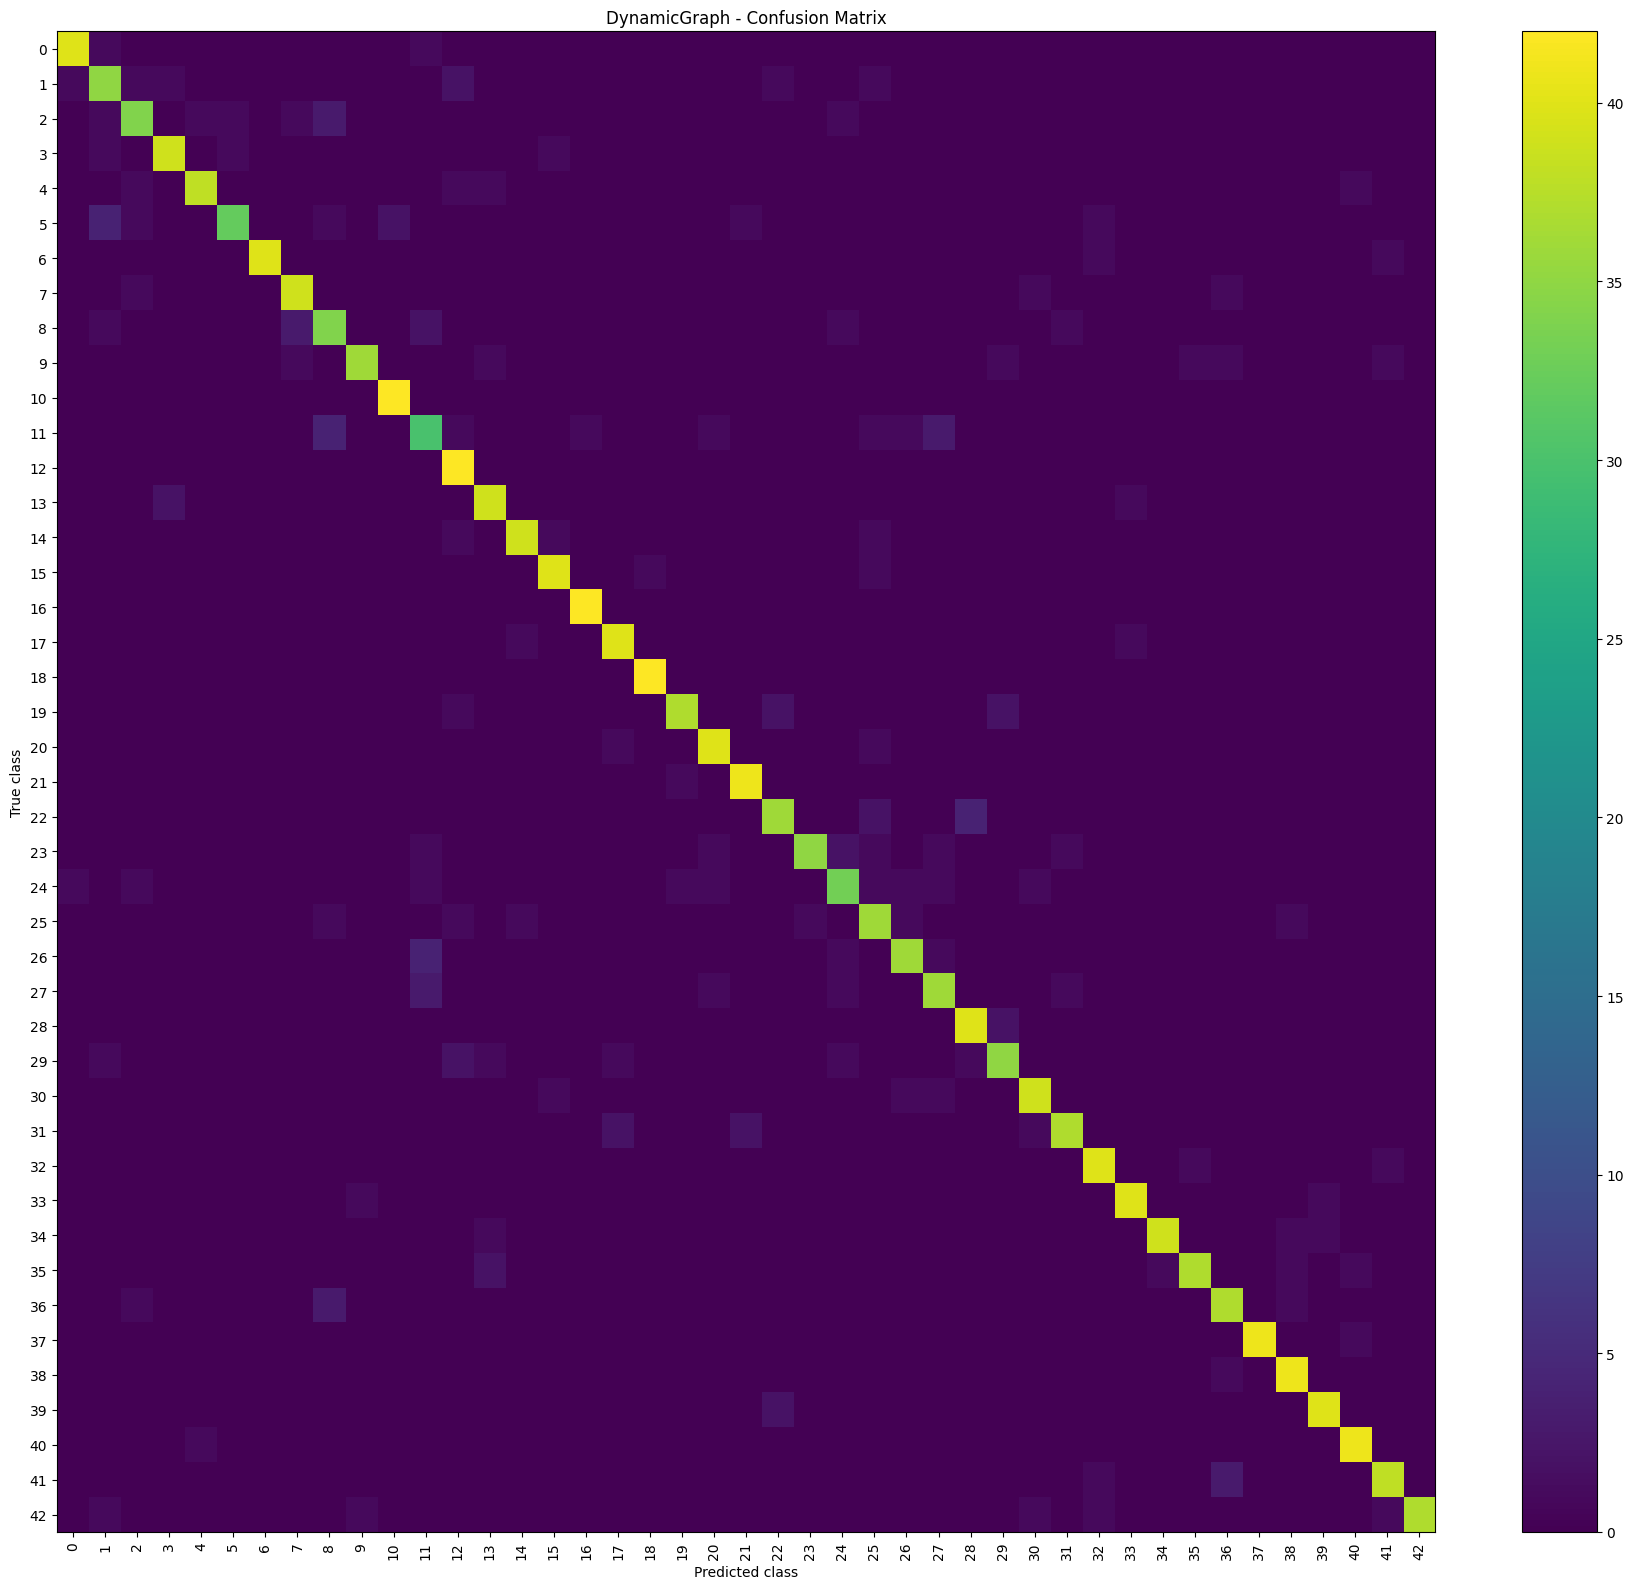


========== AGGREGATE METRICS ==========
Test samples                          : 1806
Test loss                             : 0.385025
Accuracy                              : 0.905316
Balanced accuracy                     : 0.905316
Precision macro                       : 0.907431
Recall macro                          : 0.905316
F1 macro                              : 0.905265
Precision weighted                    : 0.907431
Recall weighted                       : 0.905316
F1 weighted                           : 0.905265
Precision micro                       : 0.905316
Recall micro                          : 0.905316
F1 micro                              : 0.905316
MCC                                   : 0.903114
Cohen kappa                           : 0.903061
Top-1 accuracy                        : 0.905316
Top-3 accuracy                        : 0.967331
Top-5 accuracy                        : 0.985604
ROC-AUC macro OVR                     : 0.996901
ROC-AUC weighted OVR            

In [16]:
import os
import time
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    cohen_kappa_score,
    roc_auc_score,
    average_precision_score,
    log_loss,
)

# ============================================================
# CONFIGURATION
# ============================================================

CHECKPOINT_PATH = "/kaggle/working/best_model.pth"
OUTPUT_DIR = "/kaggle/working/model_evaluation"

os.makedirs(OUTPUT_DIR, exist_ok=True)

# Uses your existing:
# test_loader, class_ids, NUM_CLASSES, device, DynamicGraph
# apply_activation must also be defined.

# ============================================================
# 1. LOAD CHECKPOINT AND INFER ARCHITECTURE
# ============================================================

checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location="cpu",
    weights_only=True,
)

if not isinstance(checkpoint, dict):
    raise TypeError("Checkpoint must contain a state dictionary.")

if "model_state_dict" in checkpoint:
    state = checkpoint["model_state_dict"]
elif "state_dict" in checkpoint:
    state = checkpoint["state_dict"]
elif "model" in checkpoint and isinstance(checkpoint["model"], dict):
    state = checkpoint["model"]
else:
    state = checkpoint

# Handle DataParallel checkpoints.
if state and all(k.startswith("module.") for k in state):
    state = {k[7:]: v for k, v in state.items()}

required = [
    "node_weight",
    "node_bias",
    "node_rank",
    "node_alive",
    "node_activation_type",
    "edge_src",
    "edge_weight",
]

missing = [k for k in required if k not in state]
if missing:
    raise KeyError(f"Missing checkpoint tensors: {missing}")

max_nodes, feature_dim = state["node_weight"].shape
max_edges_per_node = state["edge_src"].shape[1]

# Count allocated nodes at each rank.
# node_rank is a registered buffer in your class.
ranks = state["node_rank"].long()
allocated = ranks > 0

if not allocated.any():
    raise ValueError(
        "No assigned node ranks found. This checkpoint may not contain "
        "the initialized graph topology."
    )

max_rank = int(ranks[allocated].max().item())

hidden_layers = [
    int(((ranks == rank) & allocated).sum().item())
    for rank in range(1, max_rank + 1)
]

output_nodes = int(
    ((ranks == max_rank) & state["node_alive"].bool()).sum().item()
)

input_nodes = hidden_layers[0]

print("Inferred graph configuration")
print("Max nodes:", max_nodes)
print("Feature dimension:", feature_dim)
print("Edges per node:", max_edges_per_node)
print("Layer sizes:", hidden_layers)
print("Allocated input-rank nodes:", input_nodes)
print("Active output nodes:", output_nodes)
print("Expected classes:", NUM_CLASSES)

if output_nodes != NUM_CLASSES:
    raise ValueError(
        f"The checkpoint has {output_nodes} active output nodes, "
        f"but the dataset has {NUM_CLASSES} classes."
    )

if input_nodes != NUM_NODES:
    raise ValueError(
        f"The graph expects {input_nodes} rank-1 nodes, but the loader "
        f"creates {NUM_NODES} pixel nodes per image. Check the training "
        "preprocessing and the saved graph architecture."
    )

if feature_dim != NUM_CHANNELS:
    raise ValueError(
        f"Checkpoint feature_dim={feature_dim}, but the loader provides "
        f"{NUM_CHANNELS} channels per pixel. Your forward() multiplies "
        "the input directly by node_weight, so these dimensions must match. "
        "Use the exact preprocessing/feature representation used in training."
    )

model = DynamicGraph(
    feature_dim=feature_dim,
    max_nodes=max_nodes,
    max_edges_per_node=max_edges_per_node,
    input_size=IMAGE_SIZE,
    output_size=NUM_CLASSES,
    hidden_layers=hidden_layers,
    device=device,
)

model.load_state_dict(state, strict=True)

# nodes_count is a Python attribute, not part of state_dict.
# Recover the highest allocated node index, including inactive nodes.
allocated_indices = torch.where(
    (model.node_rank > 0) | model.node_alive
)[0]

model.nodes_count = (
    int(allocated_indices.max().item()) + 1
    if allocated_indices.numel()
    else 0
)

model.eval()

print("\nCheckpoint loaded successfully.")
print("nodes_count:", model.nodes_count)
print("Evaluation device:", device)

# ============================================================
# 2. INFERENCE
# ============================================================

y_true_list = []
y_pred_list = []
prob_list = []

total_loss = 0.0
total_samples = 0
forward_times = []

# Forward uses shared activation buffers, so evaluate each image
# separately rather than passing a batch into model.forward().
with torch.inference_mode():

    # Warm-up: excluded from timing and metrics.
    warm_images, _ = next(iter(test_loader))
    warm_image = warm_images[0].to(device)

    for _ in range(2):
        _ = model(warm_image)

    if device.type == "cuda":
        torch.cuda.synchronize()

    for images, labels in test_loader:

        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        for i in range(images.shape[0]):

            image = images[i]
            label = labels[i].reshape(())

            if device.type == "cuda":
                torch.cuda.synchronize()

            start = time.perf_counter()
            scores = model(image)

            if device.type == "cuda":
                torch.cuda.synchronize()

            forward_times.append(time.perf_counter() - start)

            if isinstance(scores, (tuple, list)):
                scores = scores[0]

            if scores.shape != (NUM_CLASSES,):
                raise ValueError(
                    f"Expected [{NUM_CLASSES}] output scores, "
                    f"got {tuple(scores.shape)}."
                )

            # Cross-entropy expects raw logits, not softmax probabilities.
            loss = F.cross_entropy(
                scores.unsqueeze(0),
                label.unsqueeze(0),
                reduction="sum",
            )

            probabilities = torch.softmax(scores, dim=0)
            prediction = scores.argmax(dim=0)

            total_loss += loss.item()
            total_samples += 1

            y_true_list.append(label.item())
            y_pred_list.append(prediction.item())
            prob_list.append(probabilities.cpu().numpy())

y_true = np.asarray(y_true_list, dtype=np.int64)
y_pred = np.asarray(y_pred_list, dtype=np.int64)
y_prob = np.asarray(prob_list, dtype=np.float64)

assert len(y_true) == len(test_loader.dataset)
assert y_prob.shape == (len(y_true), NUM_CLASSES)

# ============================================================
# 3. AGGREGATE CLASSIFICATION METRICS
# ============================================================

metrics = {
    "Test samples": len(y_true),
    "Test loss": total_loss / total_samples,
    "Accuracy": accuracy_score(y_true, y_pred),
    "Balanced accuracy": balanced_accuracy_score(y_true, y_pred),

    "Precision macro": precision_score(
        y_true, y_pred, average="macro", zero_division=0
    ),
    "Recall macro": recall_score(
        y_true, y_pred, average="macro", zero_division=0
    ),
    "F1 macro": f1_score(
        y_true, y_pred, average="macro", zero_division=0
    ),

    "Precision weighted": precision_score(
        y_true, y_pred, average="weighted", zero_division=0
    ),
    "Recall weighted": recall_score(
        y_true, y_pred, average="weighted", zero_division=0
    ),
    "F1 weighted": f1_score(
        y_true, y_pred, average="weighted", zero_division=0
    ),

    "Precision micro": precision_score(
        y_true, y_pred, average="micro", zero_division=0
    ),
    "Recall micro": recall_score(
        y_true, y_pred, average="micro", zero_division=0
    ),
    "F1 micro": f1_score(
        y_true, y_pred, average="micro", zero_division=0
    ),

    "MCC": matthews_corrcoef(y_true, y_pred),
    "Cohen kappa": cohen_kappa_score(y_true, y_pred),
}

# Top-k accuracy.
for k in [1, 3, 5]:
    topk = np.argpartition(y_prob, -k, axis=1)[:, -k:]
    metrics[f"Top-{k} accuracy"] = np.mean(
        np.any(topk == y_true[:, None], axis=1)
    )

# ============================================================
# 4. ROC-AUC AND AVERAGE PRECISION
# ============================================================

y_onehot = np.eye(NUM_CLASSES, dtype=np.int32)[y_true]

try:
    metrics["ROC-AUC macro OVR"] = roc_auc_score(
        y_onehot, y_prob, average="macro"
    )
    metrics["ROC-AUC weighted OVR"] = roc_auc_score(
        y_onehot, y_prob, average="weighted"
    )
except ValueError as e:
    print("ROC-AUC unavailable:", e)

try:
    metrics["Average precision macro"] = average_precision_score(
        y_onehot, y_prob, average="macro"
    )
    metrics["Average precision weighted"] = average_precision_score(
        y_onehot, y_prob, average="weighted"
    )
except ValueError as e:
    print("Average precision unavailable:", e)

metrics["Log loss"] = log_loss(
    y_true,
    y_prob,
    labels=np.arange(NUM_CLASSES),
)

# ============================================================
# 5. PER-CLASS REPORT
# ============================================================

class_names = [str(c) for c in class_ids]

print("\n========== CLASSIFICATION REPORT ==========")

report_text = classification_report(
    y_true,
    y_pred,
    labels=np.arange(NUM_CLASSES),
    target_names=class_names,
    digits=4,
    zero_division=0,
)
print(report_text)

report_dict = classification_report(
    y_true,
    y_pred,
    labels=np.arange(NUM_CLASSES),
    target_names=class_names,
    output_dict=True,
    zero_division=0,
)


report_df = pd.DataFrame(report_dict).T

# Confusion matrix
cm = confusion_matrix(
    y_true, y_pred, labels=np.arange(NUM_CLASSES)
)

tp = np.diag(cm).astype(np.float64)
actual_positive = cm.sum(axis=1).astype(np.float64)
predicted_positive = cm.sum(axis=0).astype(np.float64)

fn = actual_positive - tp
fp = predicted_positive - tp
tn = cm.sum() - tp - fp - fn

sensitivity = np.divide(
    tp, tp + fn,
    out=np.zeros_like(tp),
    where=(tp + fn) != 0
)

specificity = np.divide(
    tn, tn + fp,
    out=np.zeros_like(tn),
    where=(tn + fp) != 0
)

# Add metrics ONLY to the 43 class rows.
for i, class_name in enumerate(class_names):
    report_df.loc[class_name, "sensitivity"] = sensitivity[i]
    report_df.loc[class_name, "specificity"] = specificity[i]

# Add macro averages to the aggregate rows.
report_df.loc["macro avg", "sensitivity"] = sensitivity.mean()
report_df.loc["macro avg", "specificity"] = specificity.mean()

# Add support-weighted averages.
support_weights = actual_positive
if support_weights.sum() > 0:
    report_df.loc["weighted avg", "sensitivity"] = np.average(
        sensitivity, weights=support_weights
    )
    report_df.loc["weighted avg", "specificity"] = np.average(
        specificity, weights=support_weights
    )

# Save the complete report.
report_df.to_csv(
    os.path.join(OUTPUT_DIR, "classification_report.csv")
)

pd.DataFrame(
    cm,
    index=class_names,
    columns=class_names
).to_csv(
    os.path.join(OUTPUT_DIR, "confusion_matrix.csv")
)

metrics["Sensitivity macro"] = sensitivity.mean()
metrics["Specificity macro"] = specificity.mean()

print("Per-class report saved successfully.")

plt.figure(figsize=(18, 16))
plt.imshow(cm, interpolation="nearest", aspect="auto")
plt.title("DynamicGraph - Confusion Matrix")
plt.colorbar()
plt.xticks(np.arange(NUM_CLASSES), class_names, rotation=90)
plt.yticks(np.arange(NUM_CLASSES), class_names)
plt.xlabel("Predicted class")
plt.ylabel("True class")
plt.tight_layout()
plt.savefig(
    os.path.join(OUTPUT_DIR, "confusion_matrix.png"),
    dpi=200,
    bbox_inches="tight",
)
plt.show()
plt.close()

# ============================================================
# 7. MODEL COMPLEXITY AND INFERENCE PERFORMANCE
# ============================================================

total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(
    p.numel() for p in model.parameters() if p.requires_grad
)

metrics["Total parameters"] = total_params
metrics["Trainable parameters"] = trainable_params
metrics["Parameters (millions)"] = total_params / 1e6
metrics["Checkpoint size (MiB)"] = (
    os.path.getsize(CHECKPOINT_PATH) / (1024 ** 2)
)

total_forward_time = sum(forward_times)

metrics["Mean forward time (ms/image)"] = (
    np.mean(forward_times) * 1000
)
metrics["Median forward time (ms/image)"] = (
    np.median(forward_times) * 1000
)
metrics["P95 forward time (ms/image)"] = (
    np.percentile(forward_times, 95) * 1000
)
metrics["Forward throughput (images/sec)"] = (
    len(y_true) / total_forward_time
    if total_forward_time > 0 else float("nan")
)

# Count active nodes and active edges in the saved graph.
metrics["Active nodes"] = int(model.node_alive.sum().item())
metrics["Active edges"] = int(model.edge_alive.sum().item())

# ============================================================
# 8. EXPORT METRICS
# ============================================================

metrics_df = pd.DataFrame(
    list(metrics.items()),
    columns=["Metric", "Value"],
)

metrics_df.to_csv(
    os.path.join(OUTPUT_DIR, "aggregate_metrics.csv"),
    index=False,
)

print("\n========== AGGREGATE METRICS ==========")
for name, value in metrics.items():
    if isinstance(value, (float, np.floating)):
        print(f"{name:38s}: {value:.6f}")
    else:
        print(f"{name:38s}: {value}")

print("\nAll results saved in:", OUTPUT_DIR)
print("1. aggregate_metrics.csv")
print("2. classification_report.csv")
print("3. confusion_matrix.csv")
print("4. confusion_matrix.png")


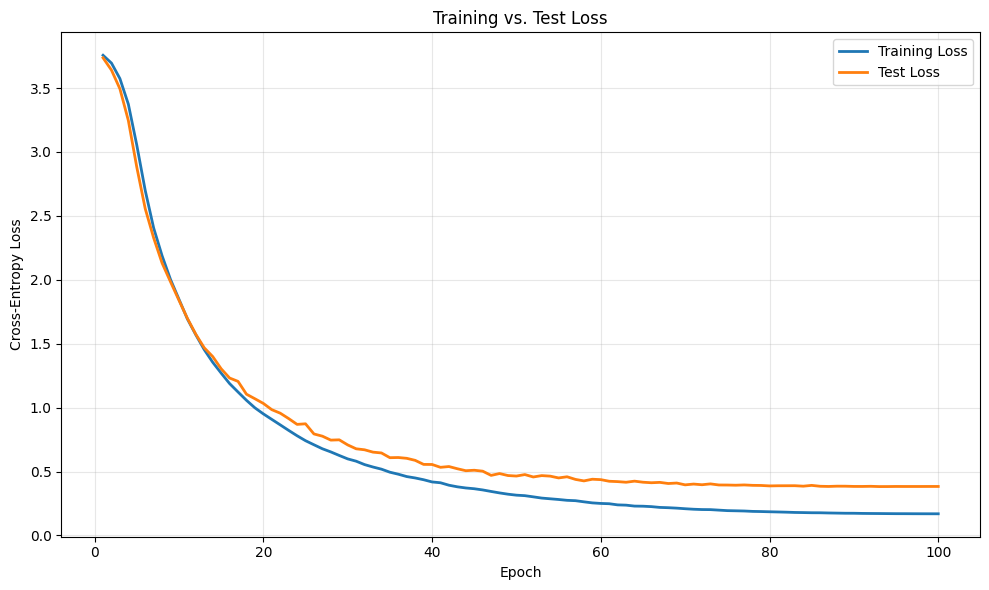

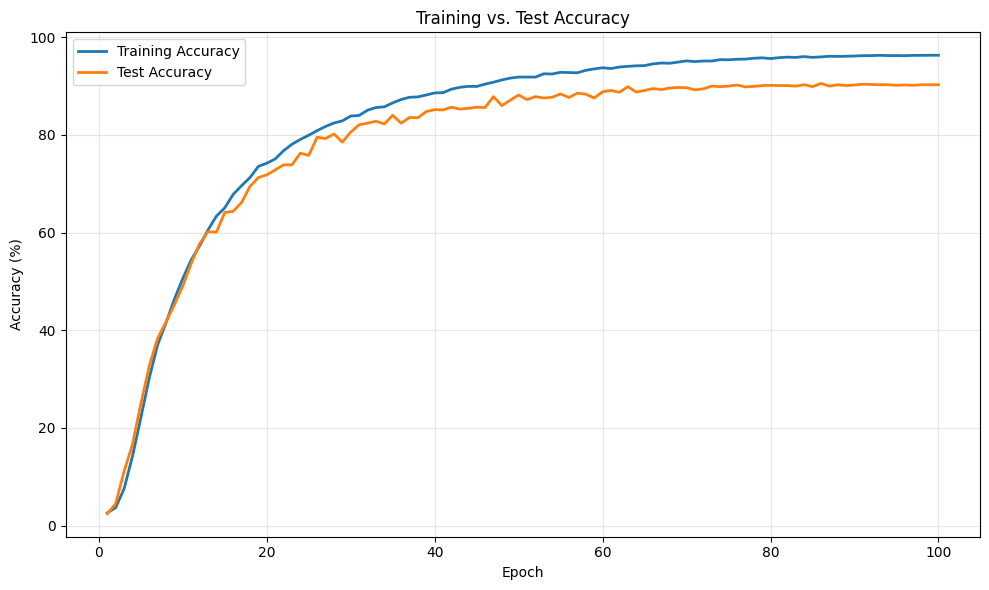

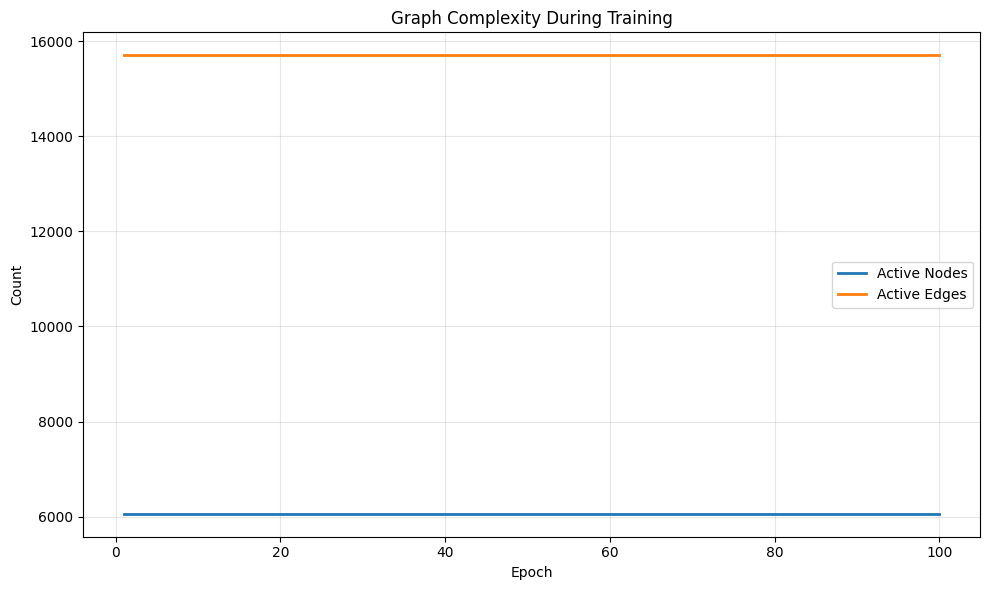

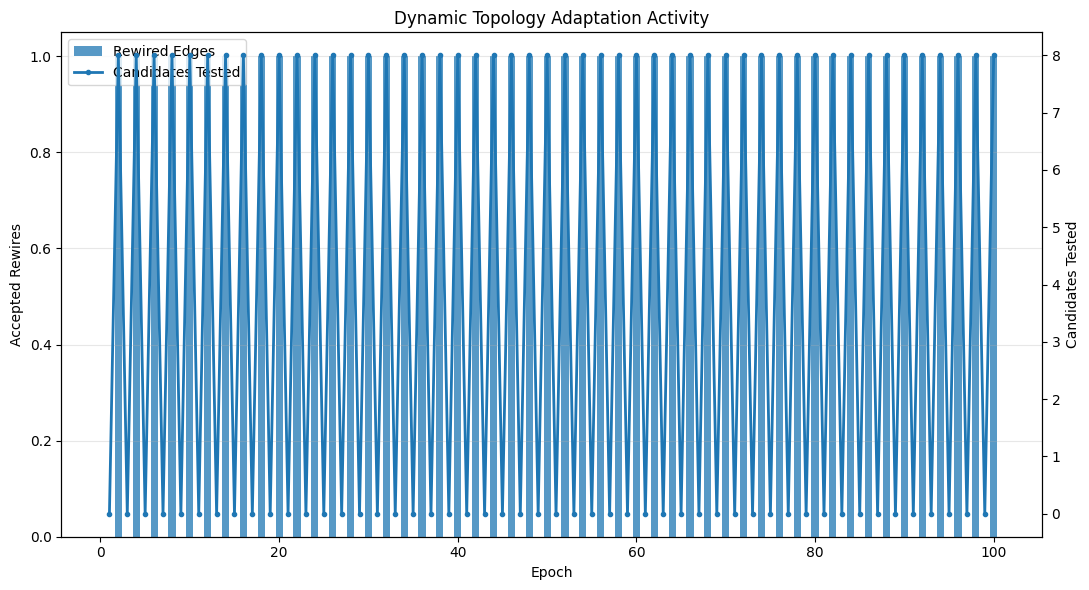

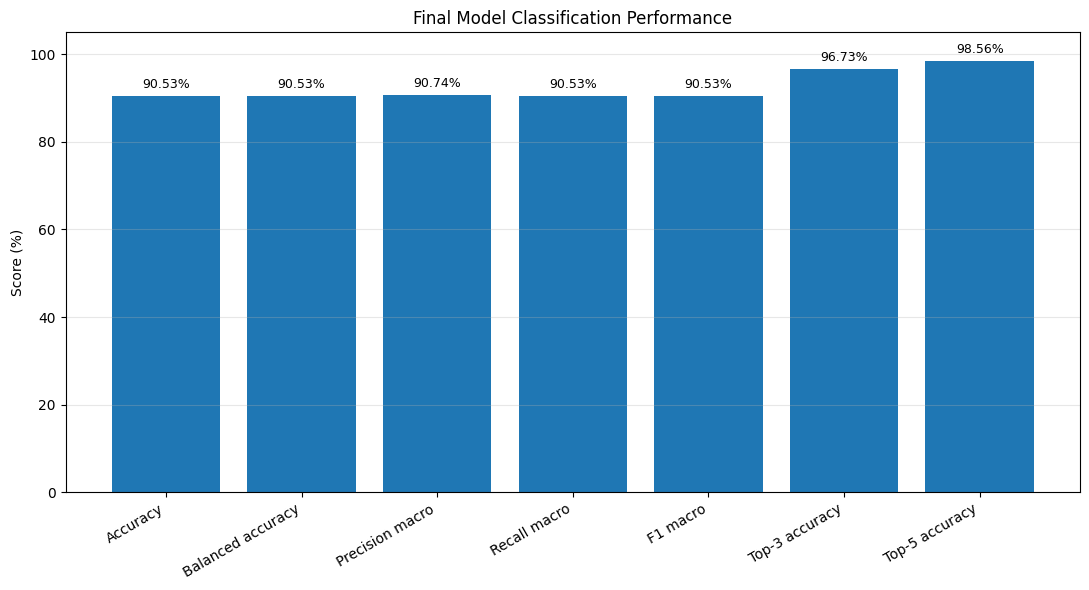


All five plots saved in: /kaggle/working/model_evaluation/plots
01_loss_curves.png
02_accuracy_curves.png
03_graph_complexity.png
04_topology_adaptation.png
05_final_metrics.png


In [17]:
# ============================================================
# 9. PLOT TRAINING HISTORY + FINAL EVALUATION METRICS
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PLOT_DIR = os.path.join(OUTPUT_DIR, "plots")
os.makedirs(PLOT_DIR, exist_ok=True)

# ------------------------------------------------------------
# INPUTS
# ------------------------------------------------------------

import json
import pandas as pd

with open("/kaggle/working/graph_history.txt", "r") as f:
    history = [json.loads(line) for line in f if line.strip()]

history_df = pd.DataFrame(history).sort_values("epoch")
epochs = history_df["epoch"]

# ------------------------------------------------------------
# PLOT 1: TRAINING AND TEST LOSS
# ------------------------------------------------------------

plt.figure(figsize=(10, 6))

plt.plot(
    epochs,
    history_df["train_loss"],
    label="Training Loss",
    linewidth=2,
)

plt.plot(
    epochs,
    history_df["test_loss"],
    label="Test Loss",
    linewidth=2,
)

plt.xlabel("Epoch")
plt.ylabel("Cross-Entropy Loss")
plt.title("Training vs. Test Loss")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(
    os.path.join(PLOT_DIR, "01_loss_curves.png"),
    dpi=300,
    bbox_inches="tight",
)
plt.show()
plt.close()


# ------------------------------------------------------------
# PLOT 2: TRAINING AND TEST ACCURACY
# ------------------------------------------------------------

plt.figure(figsize=(10, 6))

plt.plot(
    epochs,
    history_df["train_accuracy"],
    label="Training Accuracy",
    linewidth=2,
)

plt.plot(
    epochs,
    history_df["test_accuracy"],
    label="Test Accuracy",
    linewidth=2,
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("Training vs. Test Accuracy")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(
    os.path.join(PLOT_DIR, "02_accuracy_curves.png"),
    dpi=300,
    bbox_inches="tight",
)
plt.show()
plt.close()


# ------------------------------------------------------------
# PLOT 3: ACTIVE NODES AND EDGES
# ------------------------------------------------------------

plt.figure(figsize=(10, 6))

plt.plot(
    epochs,
    history_df["active_nodes"],
    label="Active Nodes",
    linewidth=2,
)

plt.plot(
    epochs,
    history_df["active_edges"],
    label="Active Edges",
    linewidth=2,
)

plt.xlabel("Epoch")
plt.ylabel("Count")
plt.title("Graph Complexity During Training")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(
    os.path.join(PLOT_DIR, "03_graph_complexity.png"),
    dpi=300,
    bbox_inches="tight",
)
plt.show()
plt.close()


# ------------------------------------------------------------
# PLOT 4: TOPOLOGY ADAPTATION ACTIVITY
# ------------------------------------------------------------

fig, ax1 = plt.subplots(figsize=(11, 6))

# Accepted rewiring events per epoch.
ax1.bar(
    epochs,
    history_df["rewired_edges"],
    label="Rewired Edges",
    alpha=0.75,
)

ax1.set_xlabel("Epoch")
ax1.set_ylabel("Accepted Rewires")
ax1.set_title("Dynamic Topology Adaptation Activity")
ax1.grid(True, axis="y", alpha=0.3)

# Number of candidates tested.
ax2 = ax1.twinx()

ax2.plot(
    epochs,
    history_df["candidates_tested"],
    label="Candidates Tested",
    linewidth=2,
    marker=".",
)

ax2.set_ylabel("Candidates Tested")

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()

ax1.legend(
    lines1 + lines2,
    labels1 + labels2,
    loc="upper left",
)

fig.tight_layout()

fig.savefig(
    os.path.join(PLOT_DIR, "04_topology_adaptation.png"),
    dpi=300,
    bbox_inches="tight",
)
plt.show()
plt.close(fig)


# ------------------------------------------------------------
# PLOT 5: FINAL CLASSIFICATION METRICS
# ------------------------------------------------------------

metric_names = [
    "Accuracy",
    "Balanced accuracy",
    "Precision macro",
    "Recall macro",
    "F1 macro",
    "Top-3 accuracy",
    "Top-5 accuracy",
]

available_metrics = {
    name: metrics[name]
    for name in metric_names
    if name in metrics
}

# Convert fractional metrics to percentages.
plot_names = list(available_metrics.keys())
plot_values = [
    available_metrics[name] * 100
    for name in plot_names
]

plt.figure(figsize=(11, 6))

bars = plt.bar(plot_names, plot_values)

plt.ylabel("Score (%)")
plt.title("Final Model Classification Performance")
plt.xticks(rotation=30, ha="right")
plt.ylim(0, 105)
plt.grid(True, axis="y", alpha=0.3)

for bar, value in zip(bars, plot_values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"{value:.2f}%",
        ha="center",
        va="bottom",
        fontsize=9,
    )

plt.tight_layout()

plt.savefig(
    os.path.join(PLOT_DIR, "05_final_metrics.png"),
    dpi=300,
    bbox_inches="tight",
)
plt.show()
plt.close()


print(f"\nAll five plots saved in: {PLOT_DIR}")
for filename in sorted(os.listdir(PLOT_DIR)):
    print(filename)

In [23]:
!zip -r plots1.zip /kaggle/working/model_evaluation/plots 

  adding: kaggle/working/model_evaluation/plots/ (stored 0%)
  adding: kaggle/working/model_evaluation/plots/04_topology_adaptation.png (deflated 6%)
  adding: kaggle/working/model_evaluation/plots/05_final_metrics.png (deflated 23%)
  adding: kaggle/working/model_evaluation/plots/01_loss_curves.png (deflated 16%)
  adding: kaggle/working/model_evaluation/plots/03_graph_complexity.png (deflated 35%)
  adding: kaggle/working/model_evaluation/plots/02_accuracy_curves.png (deflated 15%)


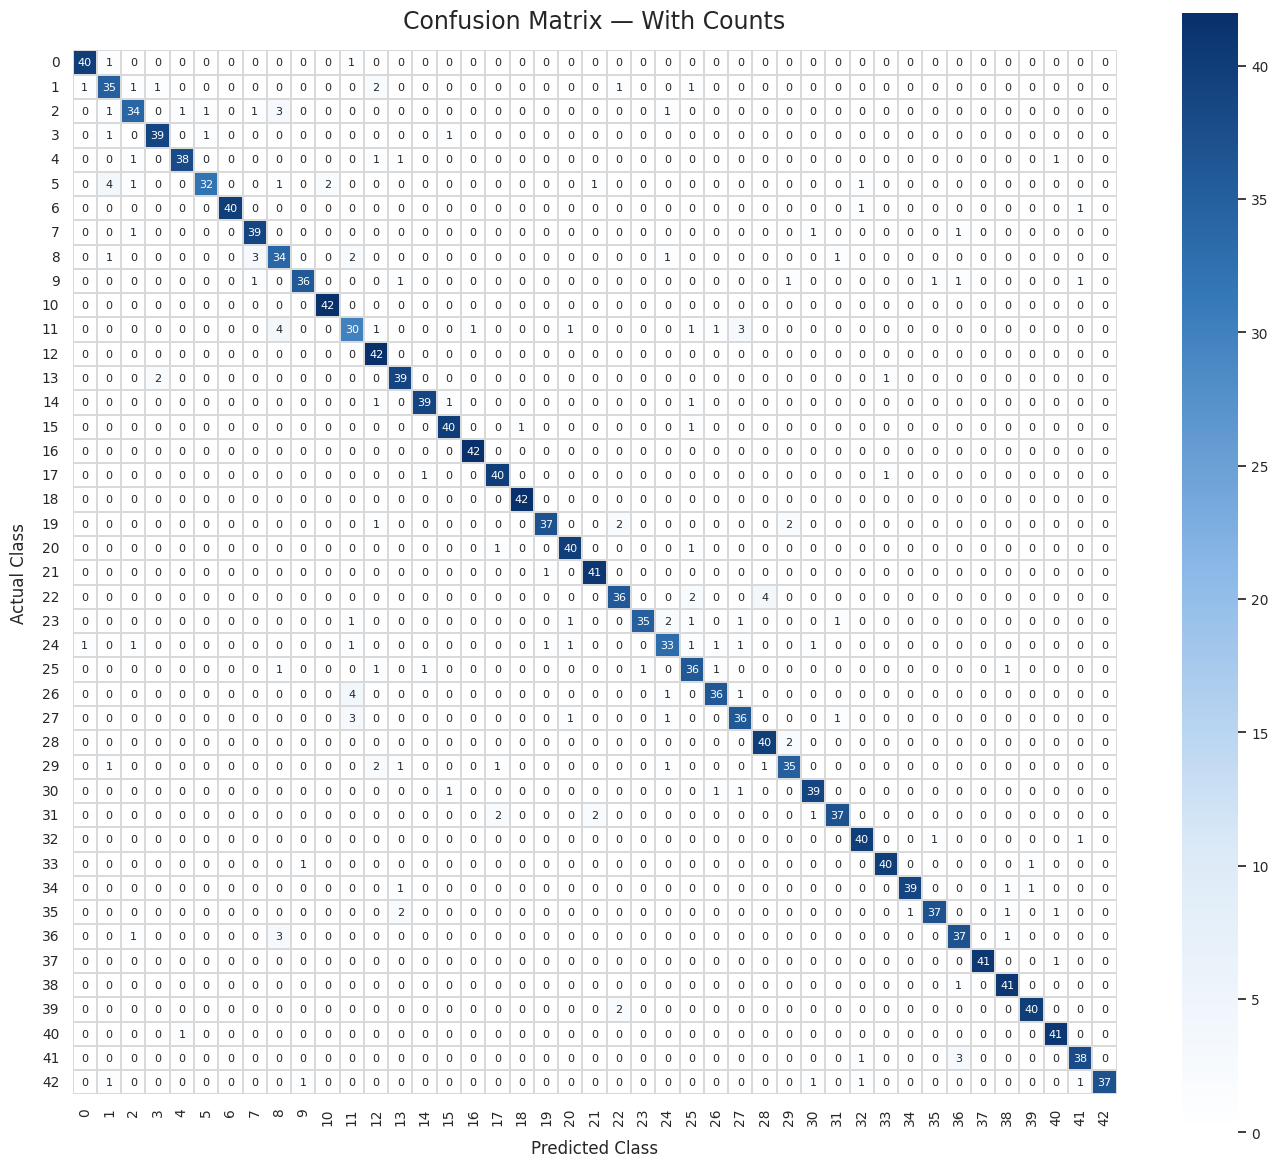

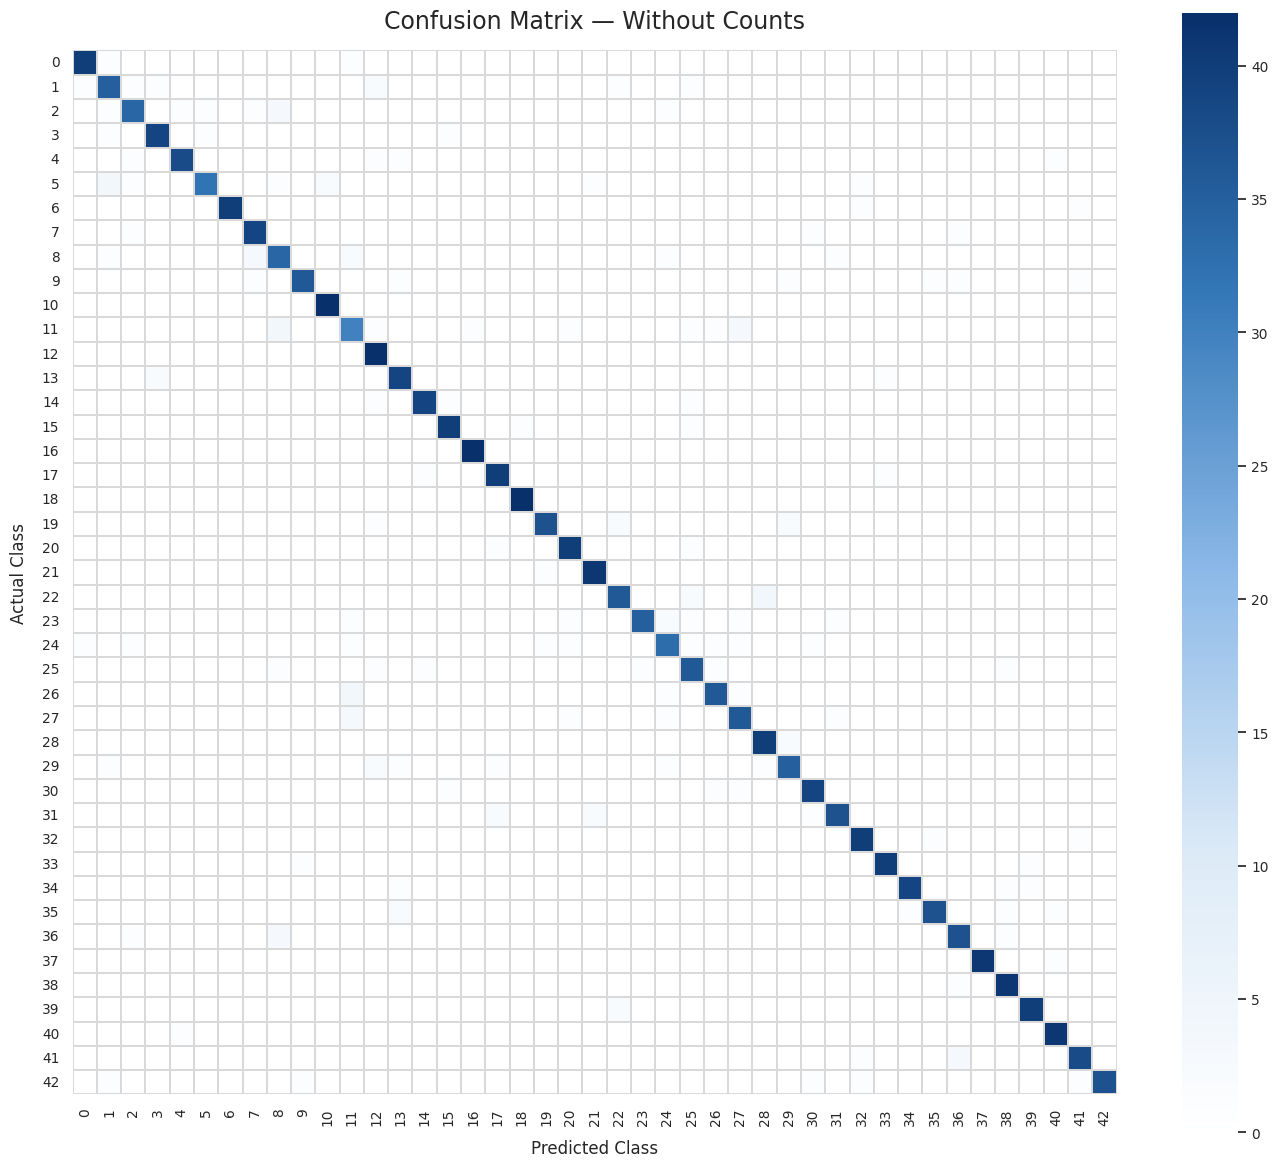

Confusion matrices saved successfully:
/kaggle/working/model_evaluation/confusion_matrix_with_numbers.png
/kaggle/working/model_evaluation/confusion_matrix_without_numbers.png


In [31]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap

# ============================================================
# CONFIGURATION
# ============================================================

OUTPUT_DIR = "/kaggle/working/model_evaluation"
CSV_PATH = os.path.join(OUTPUT_DIR, "confusion_matrix.csv")

# ============================================================
# LOAD CONFUSION MATRIX
# ============================================================

df = pd.read_csv(CSV_PATH, index_col=0)

# Ensure numeric values
df = df.apply(pd.to_numeric, errors="raise")

cm = df.to_numpy()

# Replace any NaN values with zero
cm = np.nan_to_num(cm, nan=0)

# Class names from CSV row/column labels
class_names = df.index.astype(str).tolist()

# Check dimensions
assert cm.shape[0] == cm.shape[1], (
    f"Confusion matrix must be square, got {cm.shape}"
)

# ============================================================
# CUSTOM WHITE-TO-BLUE COLORMAP
# Zero = white; larger values = darker blue
# ============================================================

blue_cmap = LinearSegmentedColormap.from_list(
    "white_to_blue",
    ["#FFFFFF", "#DCEAF7", "#8CB9E8", "#3478B8", "#08306B"]
)

sns.set_theme(style="white", font_scale=0.9)

# Consistent color scale for both plots
vmin = 0
vmax = max(1, cm.max())

# ============================================================
# 1. CONFUSION MATRIX WITH NUMBERS
# ============================================================

fig, ax = plt.subplots(figsize=(14, 12))

sns.heatmap(
    cm,
    annot=True,
    fmt="g",
    cmap=blue_cmap,
    vmin=vmin,
    vmax=vmax,
    xticklabels=class_names,
    yticklabels=class_names,
    linewidths=0.3,
    linecolor="#D9D9D9",
    cbar=True,
    square=True,
    annot_kws={"size": 8},
    ax=ax
)

ax.set_title("Confusion Matrix — With Counts", fontsize=17, pad=16)
ax.set_xlabel("Predicted Class", fontsize=12, labelpad=10)
ax.set_ylabel("Actual Class", fontsize=12, labelpad=10)

plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()

path_with_numbers = os.path.join(
    OUTPUT_DIR, "confusion_matrix_with_numbers.png"
)

plt.savefig(path_with_numbers, dpi=300, bbox_inches="tight")
plt.show()

# ============================================================
# 2. CONFUSION MATRIX WITHOUT NUMBERS
# ============================================================

fig, ax = plt.subplots(figsize=(14, 12))

sns.heatmap(
    cm,
    annot=False,
    cmap=blue_cmap,
    vmin=vmin,
    vmax=vmax,
    xticklabels=class_names,
    yticklabels=class_names,
    linewidths=0.3,
    linecolor="#D9D9D9",
    cbar=True,
    square=True,
    ax=ax
)

ax.set_title("Confusion Matrix — Without Counts", fontsize=17, pad=16)
ax.set_xlabel("Predicted Class", fontsize=12, labelpad=10)
ax.set_ylabel("Actual Class", fontsize=12, labelpad=10)

plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()

path_without_numbers = os.path.join(
    OUTPUT_DIR, "confusion_matrix_without_numbers.png"
)

plt.savefig(path_without_numbers, dpi=300, bbox_inches="tight")
plt.show()

# ============================================================
# OUTPUT
# ============================================================

print("Confusion matrices saved successfully:")
print(path_with_numbers)
print(path_without_numbers)